# Task 3 : cGan Implementation (CT condition -> PET)


In [1]:
import torch
import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import copy
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torchinfo import summary
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim


In [2]:
# Reproducibility
SEED = 42                             #to make the random operations more stable between runs
random.seed(SEED)
np.random.seed(SEED)                  #fixes randomness from numpy
torch.manual_seed(SEED)               #fixes randomness from pytorch

#if gpu exists it also fixes gpu randomness
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

#chooses whether to use GPU or CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#prints whether GPU or CPU is used
print("Using device:", device)

#if GPU is available prints its name
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce RTX 3060


## 1. Load and preprocess dataset


Total image files: 66
Total mask files: 33
Initial dataset size (number of slices before filtering): 11185
Final dataset size (number of valid slices): 676
Train samples: 474, Val samples: 135, Test samples: 67
Batches per epoch: 119


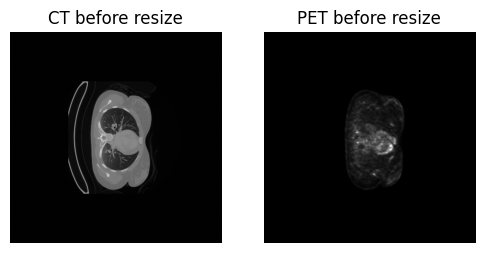

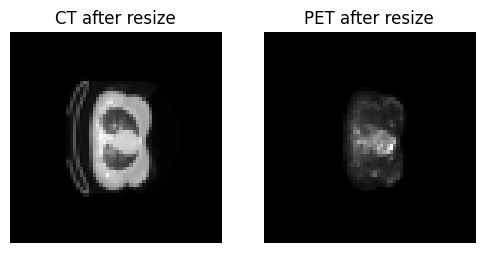

In [3]:
# Hyperparameters
image_size = 64   #all pet slices and CT slices are resized to 64 x 64
channels = 1      #PET and CT are grayscale so each has one channel
batch_size = 4    #the model trains on 4 samples at a time
n_epochs = 100
lr = 0.0002

#first momentum coefficient for Adam optimizer -> controls how much the optimizer remembers past updates
beta1 = 0.5

sample_every = 5  #every 5 epochs, generated images are shown

#weight of the L1 reconstruction loss -> makes the generator care about pixel-level similarity between generated PET and real PET
lambda_l1 = 200

#min number of samples required
min_dataset_len = 100

#dataset paths
data_root = os.path.expanduser("~/Téléchargements/autopet")
image_dir = os.path.join(data_root, "imagesTr")
mask_dir = os.path.join(data_root, "labelsTr")

#creagting a custom dataset class
class AutoPETSliceDataset(Dataset):

    #function runs when the dataset is created, It receives: image folder, mask folder, image size, minimum tumor pixels per slice
    def __init__(self, image_dir, mask_dir, image_size=64, min_mask_pixels=100):
        #stores those values inside the dataset object
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size
        self.min_mask_pixels = min_mask_pixels

        #creating CT and PET resizing
        self.resize_ct = transforms.Resize((image_size, image_size), interpolation=transforms.InterpolationMode.BILINEAR)
        self.resize_pet = transforms.Resize((image_size, image_size), interpolation=transforms.InterpolationMode.BILINEAR)
        #CT and PET are resized with bilinear interpolation because they are continuous intensity data

        image_files = sorted([f for f in os.listdir(image_dir) if f.endswith(".nii.gz")]) #gets all image files ending in .nii.gz
        mask_files = sorted([f for f in os.listdir(mask_dir) if f.endswith(".nii.gz")])   #gets all mask files ending with .nii.gz


        print(f"Total image files: {len(image_files)}")
        print(f"Total mask files: {len(mask_files)}")

        mask_map = {f.replace(".nii.gz", ""): f for f in mask_files}                      #case_name -> mask_file | example patient001 -> patient001.nii.gz

        cases = {}                                              #creates an empty dictionary to group CT and PET files by case
        for img_file in image_files:                            #loops through all image files
            base = img_file.replace(".nii.gz", "")              #removes file extension
            if base.endswith("_0000"):                          #checks if file is CT
                case_id = base[:-5]                             #removes _0000 from filename to get case ID
                cases.setdefault(case_id, {})["ct"] = img_file  #stores CT file under that case
            elif base.endswith("_0001"):                        #checks is file is PET
                case_id = base[:-5]                             #gets case ID
                cases.setdefault(case_id, {})["pet"] = img_file #stores PET file under that case

        self.samples = []   #creates an empty list, each item will later contain: CT path, PET path, mask path, slice index

        total_slices_before_filtering = 0

        for case_id, mods in cases.items(): #loops through each case

            if "ct" in mods and "pet" in mods and case_id in mask_map: #keeps only cases that have CT image, PET image and mask

                # print(f"[CASE] {case_id} | CT: {mods.get('ct')} | PET: {mods.get('pet')} | MASK: {mask_map.get(case_id)}")  #prints which case is being used (( only for debugging ))

                ct_path = os.path.join(self.image_dir, mods["ct"])          #creates full CT file path
                pet_path = os.path.join(self.image_dir, mods["pet"])        #creates full PET file path
                mask_path = os.path.join(self.mask_dir, mask_map[case_id])  #creates full mask file path

                mask_vol = nib.load(mask_path).get_fdata() #loads the 3D mask volume
                total_slices_before_filtering += mask_vol.shape[2]
                mask_sums = mask_vol.sum(axis=(0, 1))      #for each slice counts how many tumor pixels exist, result is one value per slice
                valid_slices = np.where(mask_sums > self.min_mask_pixels)[0] #ignore slices with no tumor or tiny tumor

                # print(f"[SLICES] {case_id} | Total: {mask_vol.shape[2]} | Valid: {len(valid_slices)}") #check total slices and usable slices (( debuggig only ))


                for z in valid_slices:
                    #if len(self.samples) < 10:
                    #    print(f"[ADD] z={z} | ct={os.path.basename(ct_path)} | pet={os.path.basename(pet_path)} | mask={os.path.basename(mask_path)}")  #(( debuging only ))

                    self.samples.append((ct_path, pet_path, mask_path, int(z))) #adds one usable sample, each sample means: one 2D CT slice + matching 2D PET slice selected using the tumor mask

        print(f"Initial dataset size (number of slices before filtering): {total_slices_before_filtering}")
        print(f"Final dataset size (number of valid slices): {len(self.samples)}")

    def __len__(self):      #returns dataset length | used by DataLoader
        return len(self.samples)

    def __getitem__(self, idx):   #loads one sample | is called automatically by train_loader, val_loader
        ct_path, pet_path, mask_path, z = self.samples[idx]  #gets CT path, PET path, mask path, slice number

        ct_vol = nib.load(ct_path).get_fdata()            #loads full 3D CT volume
        pet_vol = nib.load(pet_path).get_fdata()          #loads full 3D PET volume

        ct = ct_vol[:, :, z].astype(np.float32)           #extracts one 2D CT slice
        pet = pet_vol[:, :, z].astype(np.float32)         #extracts one 2D PET slice


        ct = (ct - ct.min()) / (ct.max() - ct.min() + 1e-8) #normalizes CT to [0,1] | (value - min) / (max - min)
        pet = (pet - pet.min()) / (pet.max() - pet.min() + 1e-8) #normalizes PET to [0,1] | (value - min) / (max - min)
        #detailed about normalization in text below

        ct = torch.tensor(ct).unsqueeze(0)        #converts CT from NumPy to PyTorch tensor, unsqueeze(0) adds channel dimension,shape changes: [H, W] -> [1, H, W]
        pet = torch.tensor(pet).unsqueeze(0)      #converts PET from NumPy to PyTorch tensor, unsqueeze(0) adds channel dimension,shape changes: [H, W] -> [1, H, W]


# check resizing logic: visualize before resizing
        if idx == 0:  # only visualize first sample to avoid flooding

            ct_before = ct.squeeze(0).cpu().numpy()
            pet_before = pet.squeeze(0).cpu().numpy()

            plt.figure(figsize=(6, 3))
            plt.subplot(1, 2, 1)
            plt.title("CT before resize")
            plt.imshow(ct_before, cmap="gray")
            plt.axis("off")

            plt.subplot(1, 2, 2)
            plt.title("PET before resize")
            plt.imshow(pet_before, cmap="gray")
            plt.axis("off")

            plt.show()



#resizing CT and PET to 64 x 64

        ct = self.resize_ct(ct)
        pet = self.resize_pet(pet)



# check resizing logic: visualize after resizing

        if idx == 0:
            ct_after = ct.squeeze(0).cpu().numpy()
            pet_after = pet.squeeze(0).cpu().numpy()

            plt.figure(figsize=(6, 3))
            plt.subplot(1, 2, 1)
            plt.title("CT after resize")
            plt.imshow(ct_after, cmap="gray")
            plt.axis("off")

            plt.subplot(1, 2, 2)
            plt.title("PET after resize")
            plt.imshow(pet_after, cmap="gray")
            plt.axis("off")

            plt.show()

# convert PET from [0,1] to [-1,1] to match Tanh output of generator because the generator uses Tanh at the output which produces values in [-1,1], so the target must be in the same range

        pet = pet * 2.0 - 1.0

#returns input condition = CT, target output = PET |used later in training: ((for real_ct, real_pet in train_loader))
        return ct, pet


from torch.utils.data import random_split

full_dataset = AutoPETSliceDataset(image_dir, mask_dir, image_size=image_size, min_mask_pixels=50) #creates full dataset. this calls __init__() ((changed to 50 from 100 min_mask_pixels))

#stop if dataset is too small
if  len(full_dataset) < min_dataset_len:
    raise ValueError(f"Dataset too small: {len(full_dataset)} samples found")

val_size = int(0.2 * len(full_dataset))   #validation size = 20% of dataset
test_size = int(0.1 * len(full_dataset))   #test size = 10% of dataset
train_size = len(full_dataset) - val_size - test_size #training size = remaining data


rest_dataset, test_dataset = random_split(
    full_dataset,
    [train_size + val_size, test_size],
    generator=torch.Generator().manual_seed(SEED)
)
train_dataset, val_dataset = random_split(
    rest_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)   #creates training loader | shuffle=True -> training data is shuffled | num_workers=2 -> uses 2 CPU workers to load data, it does not mean 2 GPUs | pin_memory=True -> helps faster transfer to GPU.
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)      #creates validation loader | shuffle=False -> validation data is not shuffled
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)      #creates test loader | shuffle=False -> test data is not shuffled

print(f"Train samples: {len(train_dataset)}, Val samples: {len(val_dataset)}, Test samples: {len(test_dataset)}")
print(f"Batches per epoch: {len(train_loader)}")

_ = full_dataset[0]


We normalize the PET image to make training stable by bringing values between 0 and 1. (makes training easier, keeps values in a stable range)
It is done by subtracting the minimum and dividing by the range.
However, since this is done per slice, we lose the real intensity information.
So the model learns the structure well, but not the true intensity values.

We also normalize the CT image to bring CT values between 0 and 1.
In this notebook CT is used as the condition and PET is the target image.


CT batch shape: torch.Size([4, 1, 64, 64])
PET batch shape: torch.Size([4, 1, 64, 64])
CT value range: 0.042589668184518814 to 0.7423741817474365
PET value range: -1.0 to 0.6111549139022827


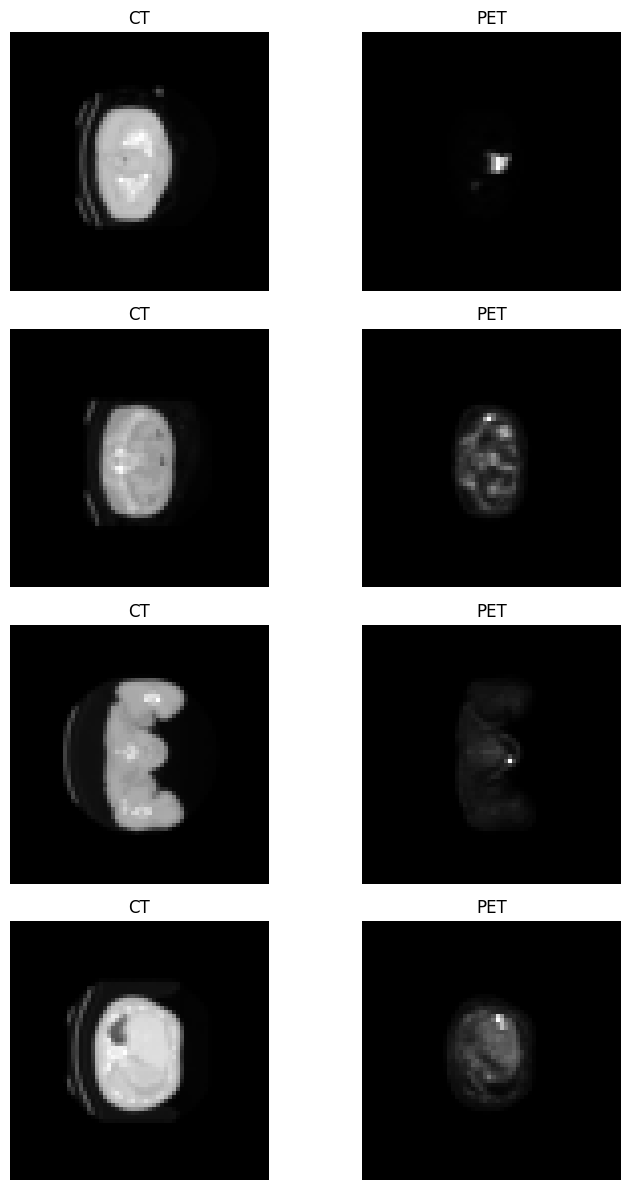

In [4]:
#dataset check
ct_images, pet_images = next(iter(train_loader)) #takes one batch from training data | this calls __getitem__
print("CT batch shape:", ct_images.shape)       #expected [batch_size, 1, 64, 64]
print("PET batch shape:", pet_images.shape)   #expected [batch_size, 1, 64, 64]
print("CT value range:", ct_images.min().item(), "to", ct_images.max().item())  #expected 0 to 1
print("PET value range:", pet_images.min().item(), "to", pet_images.max().item()) #expected -1 to 1

plt.figure(figsize=(8, 3 * min(4, ct_images.size(0))))

for i in range(min(4, ct_images.size(0))):
    plt.subplot(min(4, ct_images.size(0)), 2, 2 * i + 1)
    plt.imshow(ct_images[i][0].cpu(), cmap="gray")
    plt.title("CT")
    plt.axis("off")

    plt.subplot(min(4, ct_images.size(0)), 2, 2 * i + 2)
    plt.imshow(pet_images[i][0].cpu(), cmap="gray")
    plt.title("PET")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 2. Conditional discriminator


In [5]:
class Discriminator(nn.Module): #decides whether a PET image is real or fake given the CT condition
    def __init__(self):
        super().__init__()
        # CT is given as input because this is a conditional GAN
        # the discriminator checks if the PET image is realistic and matches the CT anatomy

        self.model = nn.Sequential(
            nn.Conv2d(2, 64, kernel_size=4, stride=2, padding=1),   #input has 2 channels:CT + PET | 64×64 -> 32×32
            nn.LeakyReLU(0.2, inplace=True), #to keep small negative values instead of killing them completely

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), #second convolution, size: 32×32 -> 16×16 | channels: 64 -> 128
            nn.BatchNorm2d(128), #stabilized activations
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), #third convolution, size: 16×16 -> 8×8 | channels: 128 -> 256
            nn.BatchNorm2d(256), #normalization
            nn.LeakyReLU(0.2, inplace=True),#activaton

            nn.Conv2d(256, 1, kernel_size=4, stride=1, padding=1), #final prediction layer, outputs one-channel map
            nn.Sigmoid() #Converts output to values between 0 and 1, meaning close to 1 = real | close to 0 = fake
        )

    def forward(self, ct_images, pet_images): #how data passes through discriminator
        x = torch.cat([ct_images, pet_images], dim=1) #combines CT and PET along channel dimension (example in text below)
        return self.model(x)


Example:

* CT:   [4,1,64,64]

* PET:  [4,1,64,64]

* x:    [4,2,64,64]


## 3. Conditional generator


In [6]:
class Generator(nn.Module): #creates a PET image from CT
    def __init__(self):
        super().__init__()
        #the CT image provides anatomical information, so the generator uses it as the condition. The task becomes learning a direct mapping from CT to PET.

        #encoder

        self.encoder = nn.Sequential( #compresses the CT image into features
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),   #1×64×64 -> 64×32×32
            nn.LeakyReLU(0.2, inplace=True),    #used in encoder to avoid losing information completely when values are negative

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), #64×32×32 -> 128×16×16
            nn.BatchNorm2d(128), #stabilizes layer outputs
            nn.LeakyReLU(0.2, inplace=True), #activation

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), #128×16×16 → 256×8×8 | this is the encoded feature map
            nn.BatchNorm2d(256), #normalization
            nn.LeakyReLU(0.2, inplace=True)#activation
        )


        #decoder

        self.decoder = nn.Sequential(    #reconstructs PET from compressed features
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),  #upsamples: 8×8 -> 16×16 | this replaced ConvTranspose2d to reduce checkerboard artifacts(systematic noise in the generated images)
            nn.Conv2d(256, 128, kernel_size=3, stride=1, padding=1),            #processes the upsampled feature map | channels: 256 -> 128 | size stays: 16×16
            nn.BatchNorm2d(128),    #normalization
            nn.ReLU(inplace=True),  #helps reconstruct clean positive features

            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),  #16×16 -> 32×32
            nn.Conv2d(128, 64, kernel_size=3, stride=1, padding=1),             #128 -> 64
            nn.BatchNorm2d(64),     #normalization
            nn.ReLU(inplace=True),  #activation

            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False), #32×32 -> 64×64
            nn.Conv2d(64, 1, kernel_size=3, stride=1, padding=1),  #creates final one-channel PET image
            nn.Tanh() #forces output range to: [-1,1] this matches the PET target after: pet = pet * 2.0 - 1.0
        )

    def forward(self, ct_images):   #defines generator input
        x = self.encoder(ct_images) #compresses CT images
        x = self.decoder(x)     #reconstructs PET
        return x                #returns generated PET


## 4. Initialize models and optimizers

In [7]:
G = Generator().to(device)      #creates generator and sends it to GPU/CPU
D = Discriminator().to(device)  #creates discriminator and sends it to GPU/CPU

criterion_adv = nn.BCELoss()  #binary cross-entropy | used for real/fake classification
criterion_l1 = nn.L1Loss()    #L1 loss | measures: average absolute difference | used to compare generated PET and real PET
                              #L1 = average of |prediction - target| ->  ensures generated image stays close to the ground truth

#Beta1 controls how much past gradients influence the current update
#The same lr is used for both networks to keep training balanced, since if one learns faster than the other, the training becomes unstable
optimizer_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(beta1, 0.999)) #optimizer for generator, updates generator weights
optimizer_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(beta1, 0.999)) #optimizer for discriminator, updates discriminator weights


# Generator summary
summary(G, input_size=(1, 1, image_size, image_size))

print("\n" + "="*50 + "\n")

# Discriminator summary
summary(D, input_size=[(1, 1, image_size, image_size), (1, 1, image_size, image_size)])


Layer (type:depth-idx)                   Output Shape              Param #
Discriminator                            [1, 1, 7, 7]              --
├─Sequential: 1-1                        [1, 1, 7, 7]              --
│    └─Conv2d: 2-1                       [1, 64, 32, 32]           2,112
│    └─LeakyReLU: 2-2                    [1, 64, 32, 32]           --
│    └─Conv2d: 2-3                       [1, 128, 16, 16]          131,200
│    └─BatchNorm2d: 2-4                  [1, 128, 16, 16]          256
│    └─LeakyReLU: 2-5                    [1, 128, 16, 16]          --
│    └─Conv2d: 2-6                       [1, 256, 8, 8]            524,544
│    └─BatchNorm2d: 2-7                  [1, 256, 8, 8]            512
│    └─LeakyReLU: 2-8                    [1, 256, 8, 8]            --
│    └─Conv2d: 2-9                       [1, 1, 7, 7]              4,097
│    └─Sigmoid: 2-10                     [1, 1, 7, 7]              --
Total params: 662,721
Trainable params: 662,721
Non-trainable param

## 5. Helper functions

In [8]:
@torch.no_grad() #no gradients are calculated, used because this is visualization, not training
def summarize_performance(generator, loader, epoch, n_samples=4): #show CT, real PET, and generated PET
    generator.eval() #sets generator to evaluation mode

    real_ct, real_pet = next(iter(loader)) #takes one batch from loader
    real_ct = real_ct.to(device)        #moves CT images to GPU/CPU
    fake_pet = generator(real_ct).cpu()    #generates fake PET and moves it to CPU for plotting

    # real_pet is in [-1,1], bring back to [0,1] for vizualization
    real_pet = ((real_pet.cpu() + 1.0) / 2.0)
    fake_pet = ((fake_pet + 1.0) / 2.0)

    #then plotting shows CT | real PET | fake PET

    plt.figure(figsize=(9, 3 * n_samples))

    for i in range(min(n_samples, real_ct.size(0))):
        plt.subplot(n_samples, 3, 3 * i + 1)
        plt.imshow(real_ct[i][0].cpu(), cmap="gray")
        plt.title("CT")
        plt.axis("off")

        plt.subplot(n_samples, 3, 3 * i + 2)
        plt.imshow(real_pet[i][0], cmap="gray")
        plt.title("Real PET")
        plt.axis("off")

        plt.subplot(n_samples, 3, 3 * i + 3)
        plt.imshow(fake_pet[i][0], cmap="gray")
        plt.title("Fake PET")
        plt.axis("off")

    plt.suptitle(f"Generated PET from CT at epoch {epoch}")
    plt.tight_layout()
    plt.show()

@torch.no_grad()
def evaluate_generator(generator, loader, device): #compute PSNR and SSIM on validation data | defines evaluation function
    generator.eval() #evaluation mode

    #lists to store metrics for each image
    psnr_values = []
    ssim_values = []

    for ct_images, real_pet in loader: #loops over validation batches
        #moves data to GPU/CPU
        ct_images = ct_images.to(device)
        real_pet = real_pet.to(device)

        #generates PET
        fake_pet = generator(ct_images)

        # convert from [-1,1] to [0,1] before computing image similarity metrics
        real_pet = (real_pet + 1.0) / 2.0
        fake_pet = (fake_pet + 1.0) / 2.0

        #converts tensors to NumPy arrays.
        real_pet = real_pet.cpu().numpy()
        fake_pet = fake_pet.cpu().numpy()

        for i in range(real_pet.shape[0]): #loops through images in the batch
            #gets one 2D image
            real_img = real_pet[i, 0]
            fake_img = fake_pet[i, 0]

            psnr_values.append(psnr(real_img, fake_img, data_range=1.0)) #computes PSNR | higher = better.
            ssim_values.append(ssim(real_img, fake_img, data_range=1.0)) #computes SSIM | closer to 1 = better

    #averages all results
    mean_psnr = np.mean(psnr_values)
    mean_ssim = np.mean(ssim_values)

    print(f"Mean PSNR on validation data: {mean_psnr:.4f}")
    print(f"Mean SSIM on validation data: {mean_ssim:.4f}")

    return mean_psnr, mean_ssim


## 6. Training loop
### Purpose

This is the main training function.

It trains:

* discriminator
* generator
* validation
* early stopping

In [9]:
def train_cgan(generator, discriminator, train_loader, val_loader, n_epochs,
               patience=15, warmup=10, min_delta=1e-6): #defines training function, inputs:generator | discriminator |training data | validation data | number of epochs | early stopping parameters

    #stores losses per epoch, used later for plotting
    history = {
        "d_loss": [], "g_loss": [],
        "d_val": [], "g_val": []
    }

#labels for discriminator, real = 0.9 instead of 1.0 to avoid overconfidence.
#intermediate values like 0.5 would make the real/fake distinction unclear.
#fake = 0

    real_label_value = 0.9
    fake_label_value = 0.0

    best_score = float("inf") #best validation generator loss so far, starts as infinity because lower is better.
    #will store best generator/discriminator weights
    best_g_weights = None
    best_d_weights = None
    wait = 0                  #counts epochs without improvement after warmup

    for epoch in range(n_epochs): #main epoch loop
        #stores batch losses for current epoch
        d_epoch_losses = []
        g_epoch_losses = []

        #training mode

        generator.train()
        discriminator.train()


        #batch loop

        for real_ct, real_pet in train_loader: #gets batches from DataLoader

            #moves tensors to GPU/CPU
            real_ct = real_ct.to(device, non_blocking=True)
            real_pet = real_pet.to(device, non_blocking=True)
            #non_blocking = True means the program does not wait unnecessarily while copying data from CPU to GPU

            # Train D
            optimizer_D.zero_grad() #clears old discriminat or gradients
            #returns out_real -> prediced value from real pet img
            out_real = discriminator(real_ct, real_pet) #discriminator sees real pair: CT + real PET, outputs prediction
            real_labels = torch.full_like(out_real, real_label_value, device=device) #creates label tensor same shape as prediction, filled with 0.9

            d_real_loss = criterion_adv(out_real, real_labels) #measures how well discriminator recognizes real PET as real


            fake_pet = generator(real_ct)  #generator creates fake PET from CT
            out_fake = discriminator(real_ct, fake_pet.detach()) #returns out_fake: prediced value from fake pet img | .detach() means do not update generator in discriminator step
            fake_labels = torch.full_like(out_fake, fake_label_value, device=device) #creates fake labels filled with 0
            d_fake_loss = criterion_adv(out_fake, fake_labels) #measures how well discriminator recognizes fake PET as fake

            #average of real and fake loss
            #we average the real and fake losses so the discriminator learns both tasks equally and the loss doesn’t become unnecessarily large
            d_loss = 0.5 * (d_real_loss + d_fake_loss)

            d_loss.backward() #calculates discriminator gradients
            optimizer_D.step()#updates discriminator weight

            # Train G
            optimizer_G.zero_grad()                               #clears old generator gradients
            fake_pet = generator(real_ct)                         #generates fake PET again
            out_fake = discriminator(real_ct, fake_pet)           #discriminator evaluates fake PET | no .detach() here because generator must learn
            real_labels_g = torch.full_like(out_fake, real_label_value, device=device) #generator wants fake PET to be classified as real => target label = 0.9
            adv_loss = criterion_adv(out_fake, real_labels_g)     #adversarial loss, it tells generator to make fake PET look real
            l1_loss = criterion_l1(fake_pet, real_pet)            #compares fake PET and real PET pixel by pixel, it tells generator to stay close to the correct PET.
            g_loss = adv_loss + lambda_l1 * l1_loss               #final generator loss. 2 parts: adv_loss -> realism, L1 loss -> similarity to real PET


#debug print block : runs only for the first batch of first epoch, prints shapes and loss values to understand the generator step

            if epoch == 0 and len(g_epoch_losses) == 0:
                print("G step: old gradients cleared")
                print("Generated PET shape:", fake_pet.shape)
                print("Discriminator output shape:", out_fake.shape)
                print("Discriminator output mean:", out_fake.mean().item())
                print("Generator target label:", real_label_value)
                print("Adversarial loss:", adv_loss.item())
                print("L1 loss:", l1_loss.item())
                print("Total generator loss:", g_loss.item())

            g_loss.backward()  #calculates generator gradients
            optimizer_G.step() #updates generator weights

            #stores batch losses | .item() converts tensor to normal number
            d_epoch_losses.append(d_loss.item())
            g_epoch_losses.append(g_loss.item())


        #end of epoch

        #stores average training losses for the epoch
        history["d_loss"].append(np.mean(d_epoch_losses))
        history["g_loss"].append(np.mean(g_epoch_losses))


        # validation

        #evaluation mode
        generator.eval()
        discriminator.eval()

        d_val_losses, g_val_losses = [], []  #stores validation losses

        with torch.no_grad(): #no gradients during validation
            #validation loop repeats the same loss calculations, but does not update weights
            for real_ct, real_pet in val_loader:
                real_ct = real_ct.to(device, non_blocking=True)
                real_pet = real_pet.to(device, non_blocking=True)

                out_real = discriminator(real_ct, real_pet)
                real_labels = torch.full_like(out_real, real_label_value, device=device)
                d_real_loss = criterion_adv(out_real, real_labels)

                fake_pet = generator(real_ct)
                out_fake = discriminator(real_ct, fake_pet)
                fake_labels = torch.full_like(out_fake, fake_label_value, device=device)
                d_fake_loss = criterion_adv(out_fake, fake_labels)

                d_val = 0.5 * (d_real_loss + d_fake_loss)

                real_labels_g = torch.full_like(out_fake, real_label_value, device=device)
                g_val = criterion_adv(out_fake, real_labels_g) + lambda_l1 * criterion_l1(fake_pet, real_pet)

                d_val_losses.append(d_val.item())
                g_val_losses.append(g_val.item())

        #stores validation losses
        history["d_val"].append(np.mean(d_val_losses))
        history["g_val"].append(np.mean(g_val_losses))


        val_score = history["g_val"][-1] #takes latest generator validation loss | used for early stopping
        #list where we store generator validation loss for each epoch, [-1] = last element, so val_score = history["g_val"][-1] means take the latest generator validation loss

        print(
            f"Epoch [{epoch+1}/{n_epochs}] | "
            f"D: {history['d_loss'][-1]:.4f} | G: {history['g_loss'][-1]:.4f} | "
            f"D_val: {history['d_val'][-1]:.4f} | G_val: {history['g_val'][-1]:.4f}"
        )   #prints epoch losses

        if val_score < best_score - min_delta: #checks if validation generator loss improved enough
            best_score = val_score   #updates best score

            #saves best weights
            best_g_weights = copy.deepcopy(generator.state_dict())
            best_d_weights = copy.deepcopy(discriminator.state_dict())

            #resets patience counter
            wait = 0

        elif epoch + 1 > warmup:  #if no improvement and warmup is finished, increase wait
            wait += 1

        #checks if still inside warmup
        if epoch < warmup:
            print(f"[Epoch {epoch+1}] WARMUP ({epoch+1}/{warmup})") #prints warmup status
        else:   #after warmup
            if wait == 0: #means improvement happened
                print(f"[Epoch {epoch+1}] PATIENCE | improvement detected → reset wait") #prints that patience reset
            else:
                print(f"[Epoch {epoch+1}] PATIENCE | wait = {wait}/{patience}")    #prints patience counter

        if (epoch + 1) % sample_every == 0: #every 5 epochs
            summarize_performance(generator, val_loader, epoch + 1) #shows generated images on validation data

        if wait >= patience: #if no improvement for too many epochs
            print(f"Early stopping at epoch {epoch+1}. Restoring best weights.") #prints early stopping message

            #restores best model weights
            generator.load_state_dict(best_g_weights)
            discriminator.load_state_dict(best_d_weights)

            #stops training
            break

    #after training checks if best weights exist
    if best_g_weights is not None:
        #restores best weights even if early stopping did not trigger
        generator.load_state_dict(best_g_weights)
        discriminator.load_state_dict(best_d_weights)
        print("Best weights restored.")

    #returns losses
    return history


## 7. Train the cGAN

G step: old gradients cleared
Generated PET shape: torch.Size([4, 1, 64, 64])
Discriminator output shape: torch.Size([4, 1, 7, 7])
Discriminator output mean: 0.39645251631736755
Generator target label: 0.9
Adversarial loss: 0.9130264520645142
L1 loss: 0.9085049629211426
Total generator loss: 182.614013671875
Epoch [1/100] | D: 0.5748 | G: 25.3385 | D_val: 0.6449 | G_val: 6.0076
[Epoch 1] WARMUP (1/10)
Epoch [2/100] | D: 0.6105 | G: 4.8006 | D_val: 1.8805 | G_val: 3.4055
[Epoch 2] WARMUP (2/10)
Epoch [3/100] | D: 0.5593 | G: 3.9699 | D_val: 0.7202 | G_val: 3.6768
[Epoch 3] WARMUP (3/10)
Epoch [4/100] | D: 0.5464 | G: 3.7348 | D_val: 0.6409 | G_val: 3.5654
[Epoch 4] WARMUP (4/10)
Epoch [5/100] | D: 0.4844 | G: 3.7781 | D_val: 0.8033 | G_val: 4.3566
[Epoch 5] WARMUP (5/10)


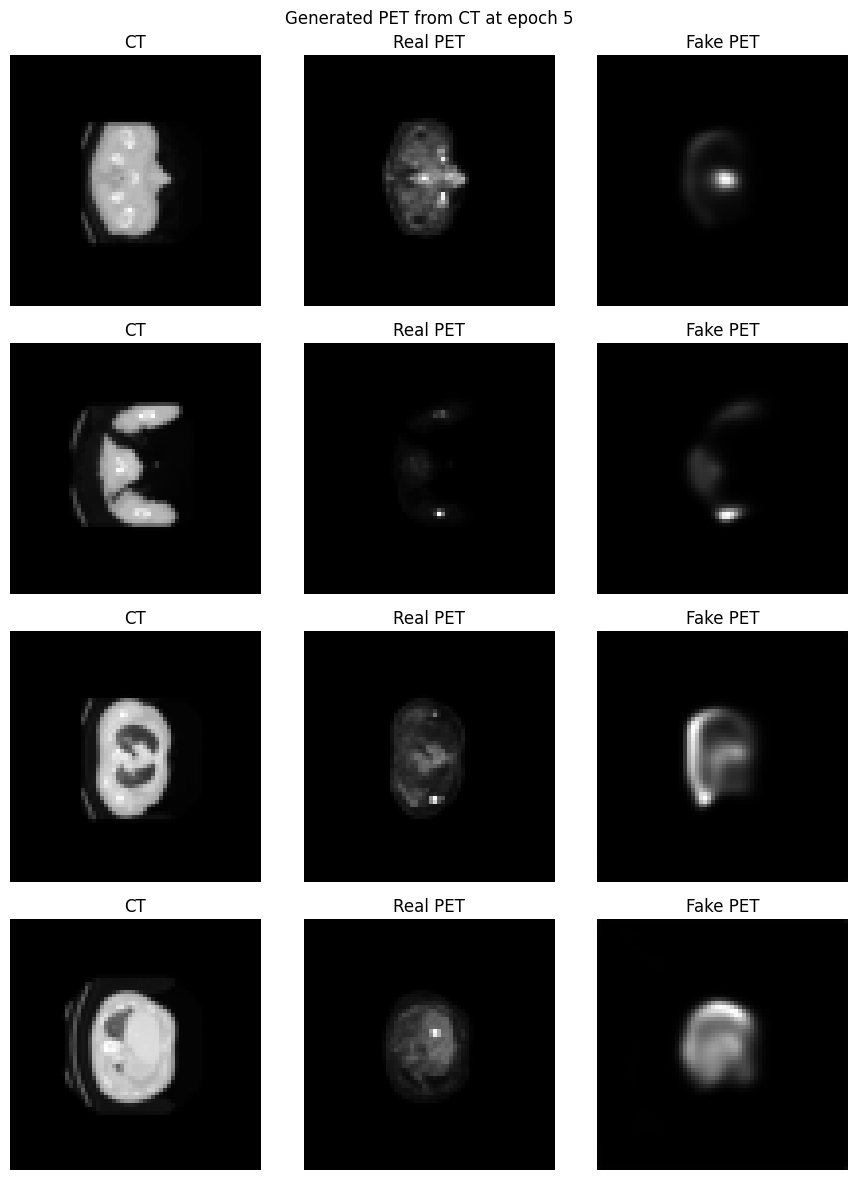

Epoch [6/100] | D: 0.4587 | G: 3.8154 | D_val: 0.6601 | G_val: 3.4473
[Epoch 6] WARMUP (6/10)
Epoch [7/100] | D: 0.4468 | G: 3.8193 | D_val: 0.8700 | G_val: 3.3850
[Epoch 7] WARMUP (7/10)
Epoch [8/100] | D: 0.4394 | G: 3.8430 | D_val: 1.1614 | G_val: 4.7364
[Epoch 8] WARMUP (8/10)
Epoch [9/100] | D: 0.4165 | G: 3.8313 | D_val: 0.9809 | G_val: 4.6001
[Epoch 9] WARMUP (9/10)
Epoch [10/100] | D: 0.4047 | G: 3.9868 | D_val: 0.9301 | G_val: 4.1528
[Epoch 10] WARMUP (10/10)


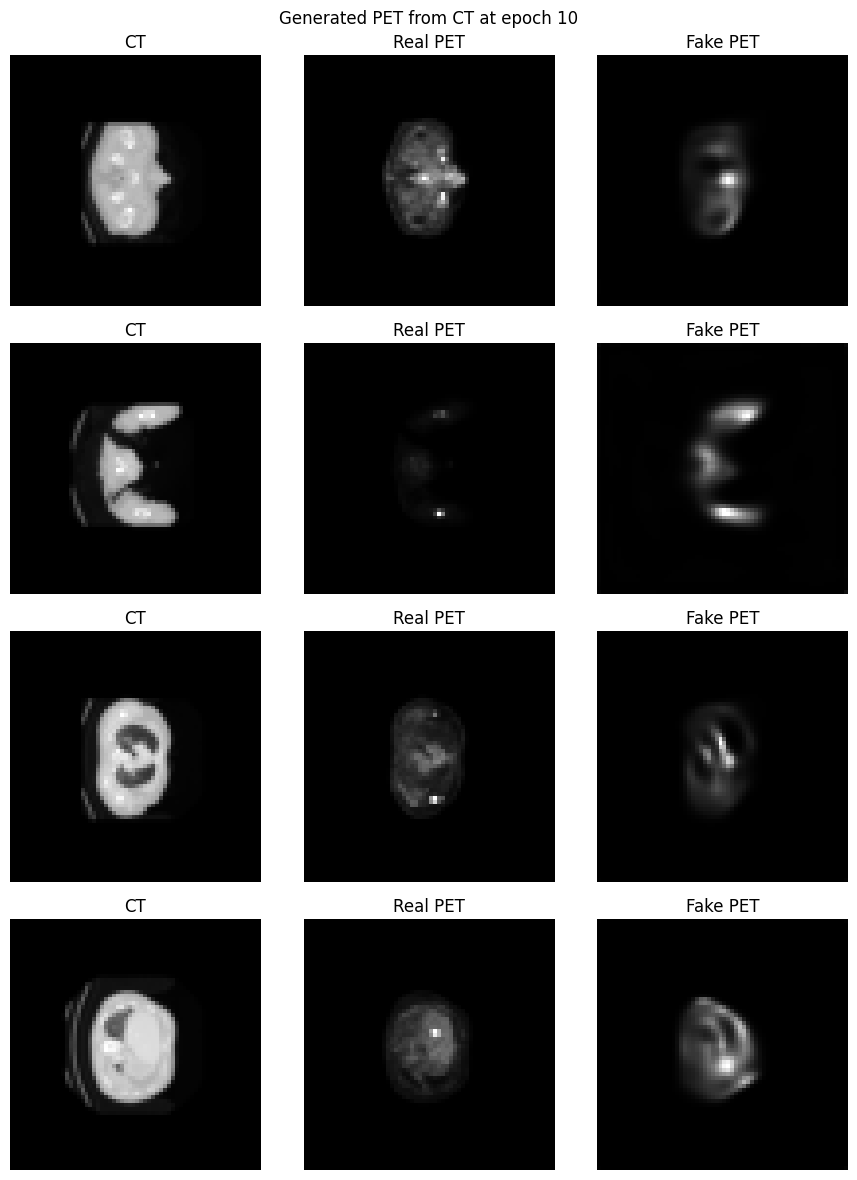

Epoch [11/100] | D: 0.3954 | G: 3.9617 | D_val: 0.6853 | G_val: 3.4989
[Epoch 11] PATIENCE | wait = 1/50
Epoch [12/100] | D: 0.3879 | G: 3.9196 | D_val: 0.6534 | G_val: 3.0806
[Epoch 12] PATIENCE | improvement detected → reset wait
Epoch [13/100] | D: 0.4013 | G: 3.9019 | D_val: 0.6313 | G_val: 2.9327
[Epoch 13] PATIENCE | improvement detected → reset wait
Epoch [14/100] | D: 0.3709 | G: 3.9646 | D_val: 0.6145 | G_val: 2.8932
[Epoch 14] PATIENCE | improvement detected → reset wait
Epoch [15/100] | D: 0.3926 | G: 3.8937 | D_val: 0.8051 | G_val: 3.6626
[Epoch 15] PATIENCE | wait = 1/50


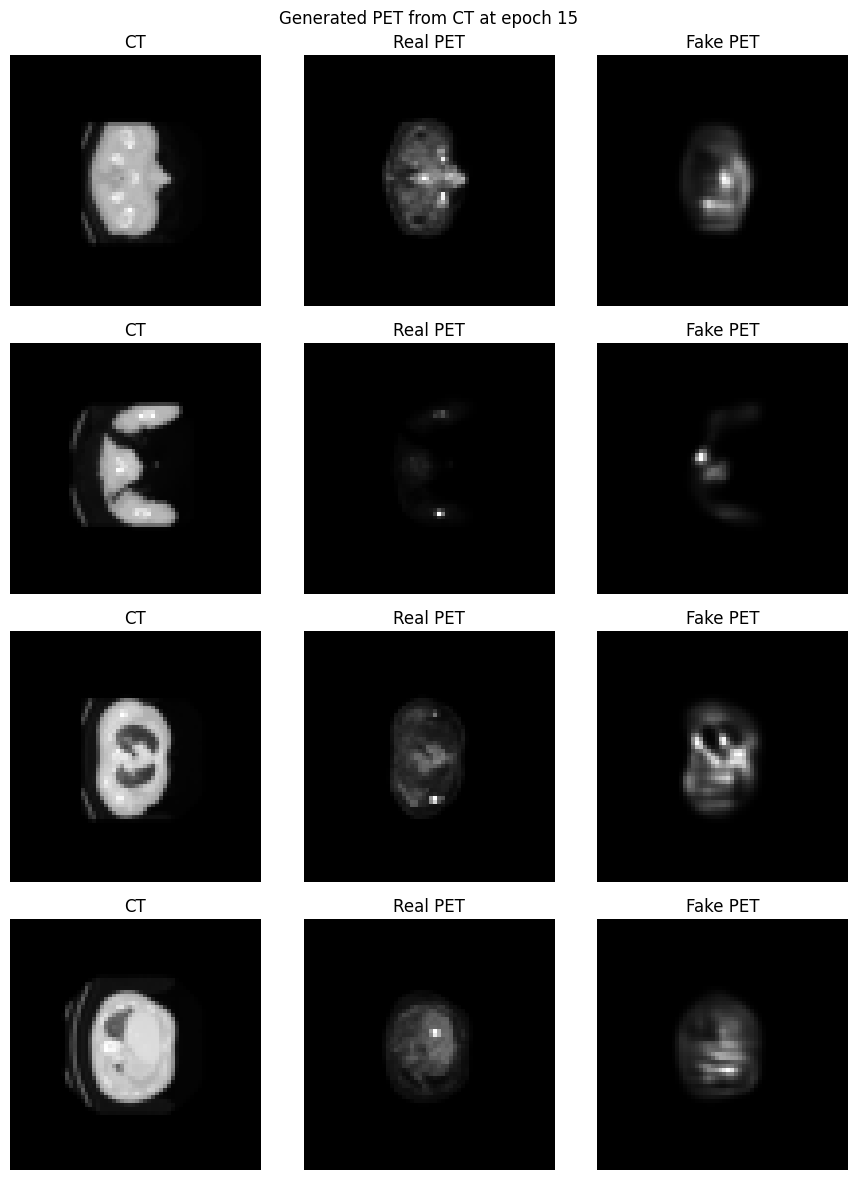

Epoch [16/100] | D: 0.3993 | G: 3.7676 | D_val: 0.7370 | G_val: 2.8119
[Epoch 16] PATIENCE | improvement detected → reset wait
Epoch [17/100] | D: 0.3975 | G: 3.7502 | D_val: 0.6530 | G_val: 3.4448
[Epoch 17] PATIENCE | wait = 1/50
Epoch [18/100] | D: 0.3688 | G: 3.9680 | D_val: 0.6551 | G_val: 3.1379
[Epoch 18] PATIENCE | wait = 2/50
Epoch [19/100] | D: 0.3740 | G: 3.8929 | D_val: 0.7749 | G_val: 3.6046
[Epoch 19] PATIENCE | wait = 3/50
Epoch [20/100] | D: 0.3523 | G: 3.9623 | D_val: 0.6697 | G_val: 3.5247
[Epoch 20] PATIENCE | wait = 4/50


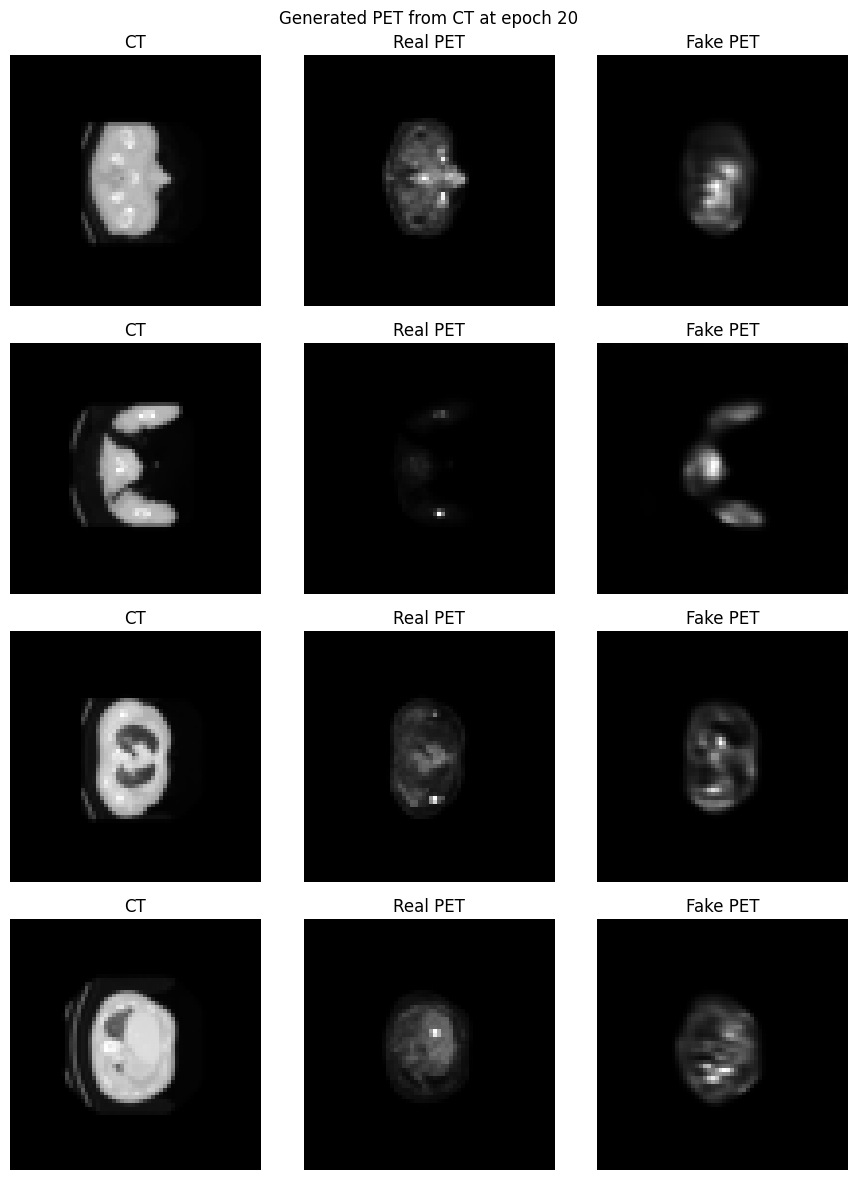

Epoch [21/100] | D: 0.3584 | G: 3.9237 | D_val: 1.0063 | G_val: 2.2951
[Epoch 21] PATIENCE | improvement detected → reset wait
Epoch [22/100] | D: 0.3382 | G: 3.9694 | D_val: 0.6979 | G_val: 2.6251
[Epoch 22] PATIENCE | wait = 1/50
Epoch [23/100] | D: 0.3557 | G: 3.9301 | D_val: 0.7677 | G_val: 3.6634
[Epoch 23] PATIENCE | wait = 2/50
Epoch [24/100] | D: 0.3091 | G: 4.1344 | D_val: 0.8902 | G_val: 4.0792
[Epoch 24] PATIENCE | wait = 3/50
Epoch [25/100] | D: 0.3145 | G: 4.1902 | D_val: 0.7725 | G_val: 3.5430
[Epoch 25] PATIENCE | wait = 4/50


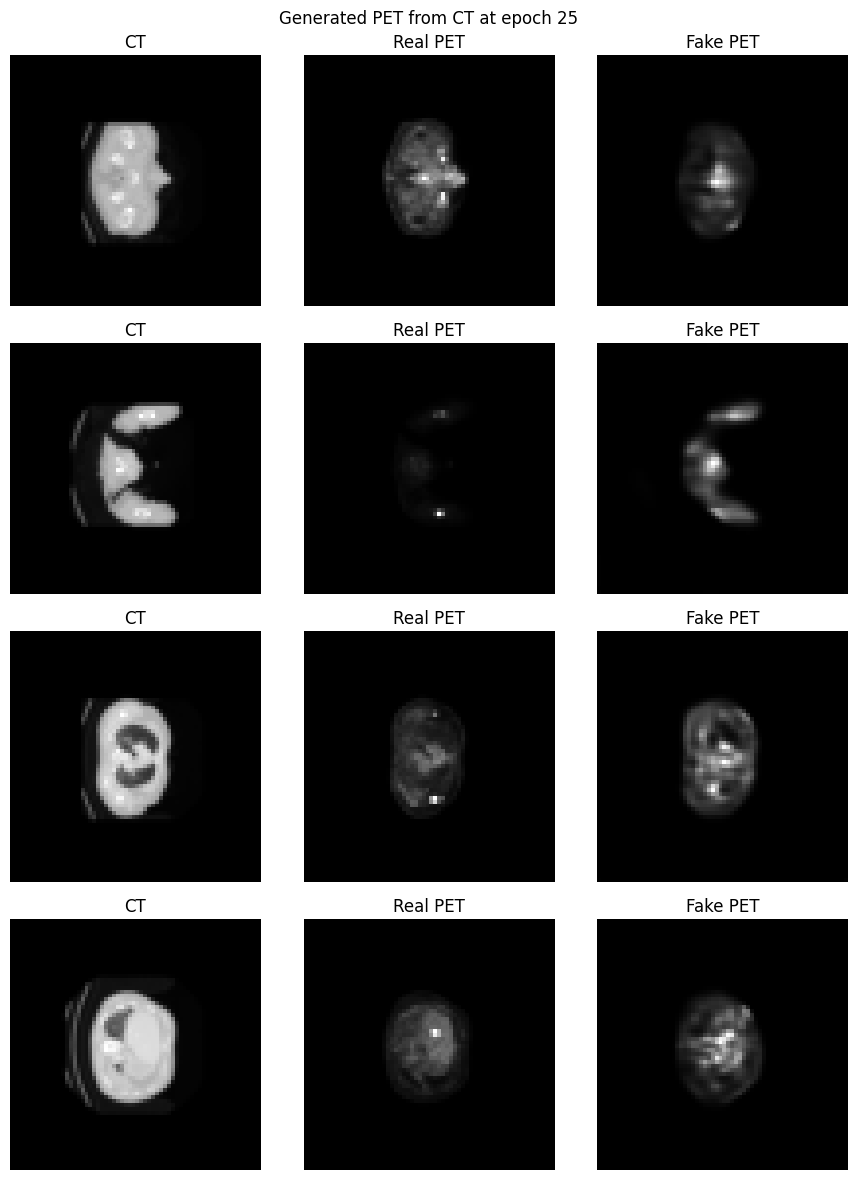

Epoch [26/100] | D: 0.3143 | G: 4.1112 | D_val: 1.6235 | G_val: 5.5983
[Epoch 26] PATIENCE | wait = 5/50
Epoch [27/100] | D: 0.3022 | G: 4.1529 | D_val: 1.6188 | G_val: 5.4926
[Epoch 27] PATIENCE | wait = 6/50
Epoch [28/100] | D: 0.3377 | G: 3.9916 | D_val: 0.6265 | G_val: 2.9256
[Epoch 28] PATIENCE | wait = 7/50
Epoch [29/100] | D: 0.2944 | G: 4.1527 | D_val: 0.6699 | G_val: 2.8971
[Epoch 29] PATIENCE | wait = 8/50
Epoch [30/100] | D: 0.3422 | G: 4.0354 | D_val: 1.5408 | G_val: 5.4590
[Epoch 30] PATIENCE | wait = 9/50


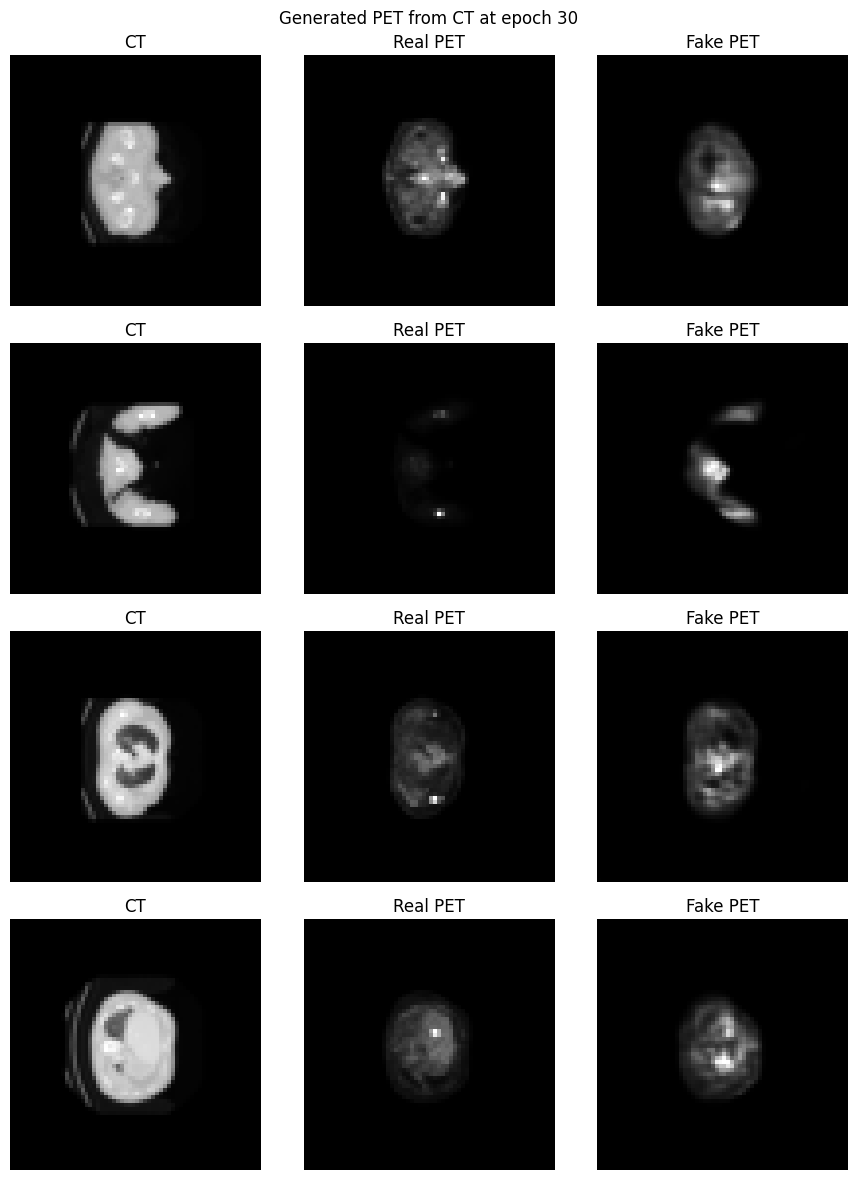

Epoch [31/100] | D: 0.3257 | G: 4.0555 | D_val: 0.8149 | G_val: 3.6071
[Epoch 31] PATIENCE | wait = 10/50
Epoch [32/100] | D: 0.3367 | G: 3.9674 | D_val: 0.8877 | G_val: 3.6621
[Epoch 32] PATIENCE | wait = 11/50
Epoch [33/100] | D: 0.3004 | G: 4.0303 | D_val: 0.6816 | G_val: 2.9936
[Epoch 33] PATIENCE | wait = 12/50
Epoch [34/100] | D: 0.3093 | G: 4.0619 | D_val: 0.6977 | G_val: 2.9177
[Epoch 34] PATIENCE | wait = 13/50
Epoch [35/100] | D: 0.2887 | G: 4.1677 | D_val: 1.1405 | G_val: 4.6380
[Epoch 35] PATIENCE | wait = 14/50


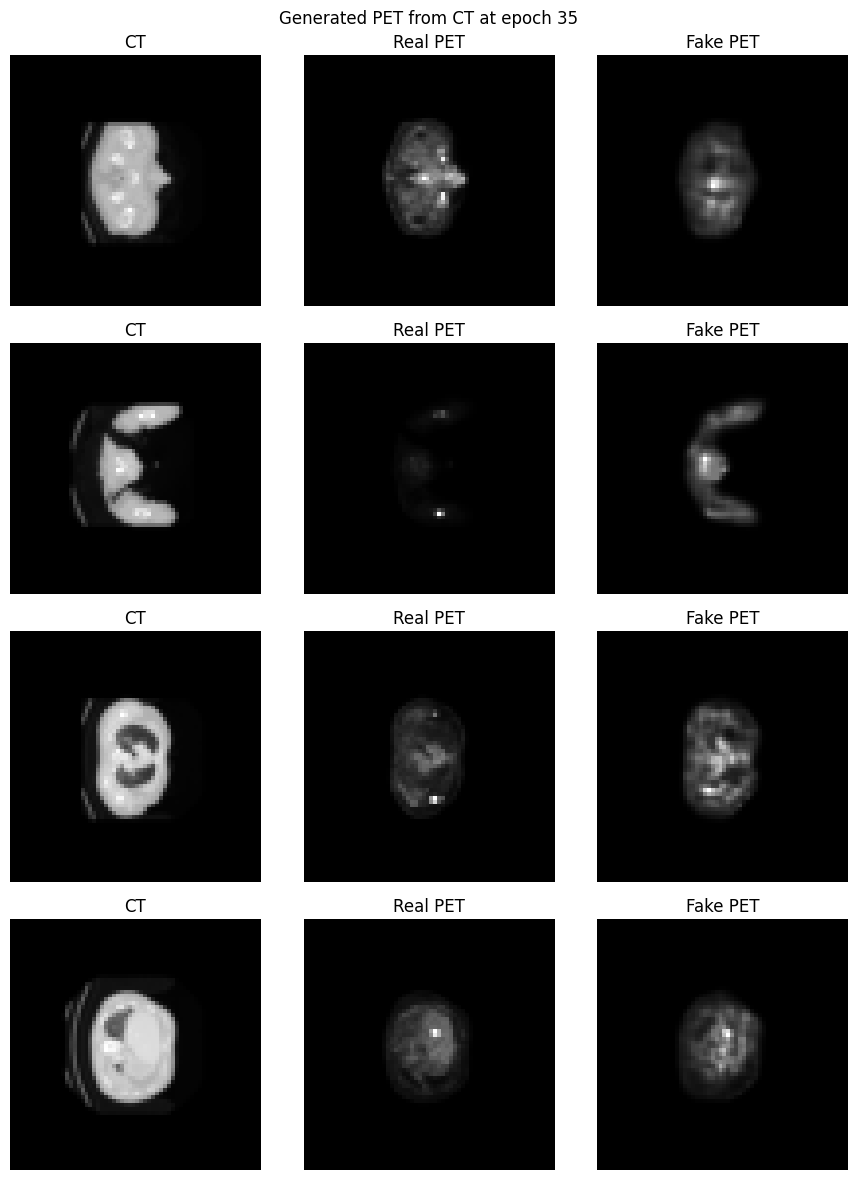

Epoch [36/100] | D: 0.3177 | G: 4.1884 | D_val: 0.8555 | G_val: 2.1693
[Epoch 36] PATIENCE | improvement detected → reset wait
Epoch [37/100] | D: 0.3177 | G: 4.0365 | D_val: 0.8661 | G_val: 3.8470
[Epoch 37] PATIENCE | wait = 1/50
Epoch [38/100] | D: 0.2945 | G: 4.1569 | D_val: 0.6584 | G_val: 3.1730
[Epoch 38] PATIENCE | wait = 2/50
Epoch [39/100] | D: 0.3128 | G: 4.0503 | D_val: 1.1563 | G_val: 4.3775
[Epoch 39] PATIENCE | wait = 3/50
Epoch [40/100] | D: 0.3237 | G: 4.0119 | D_val: 0.7831 | G_val: 2.4719
[Epoch 40] PATIENCE | wait = 4/50


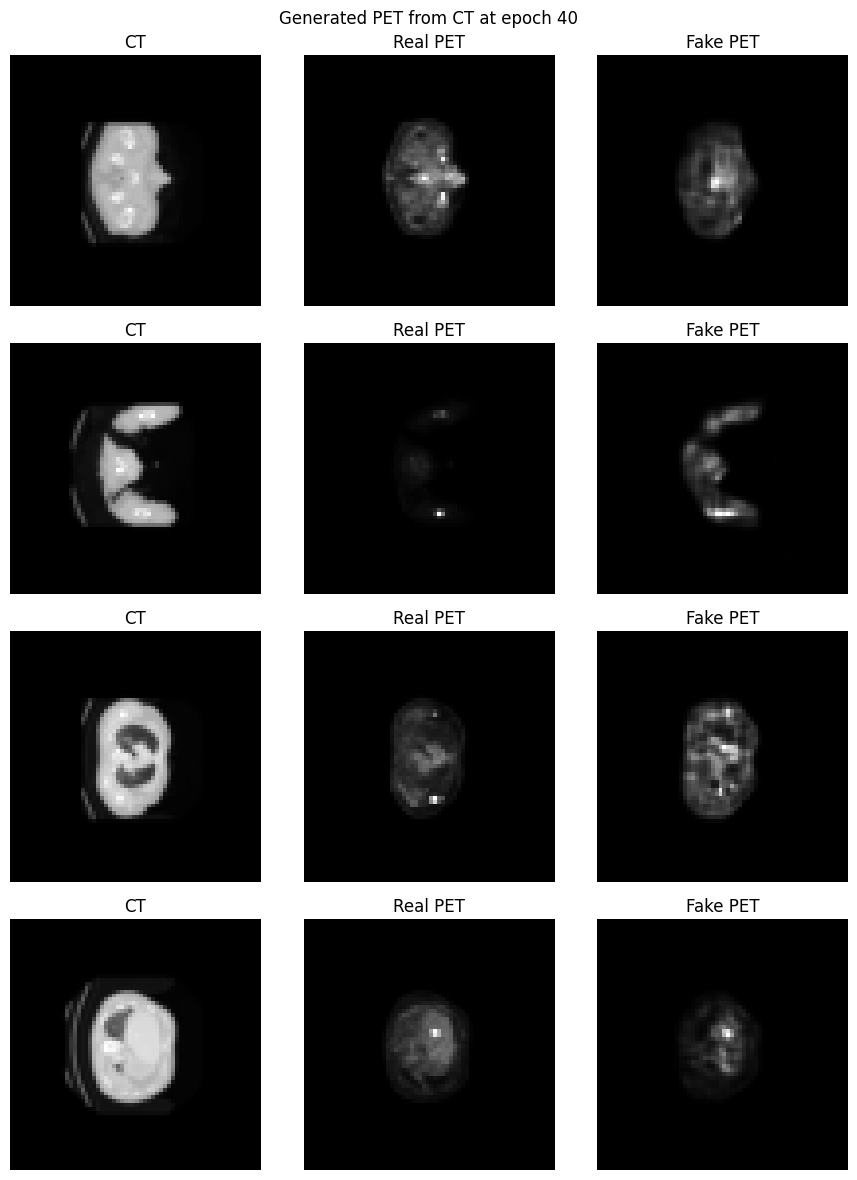

Epoch [41/100] | D: 0.2823 | G: 4.2097 | D_val: 0.6132 | G_val: 3.1034
[Epoch 41] PATIENCE | wait = 5/50
Epoch [42/100] | D: 0.3053 | G: 4.1866 | D_val: 1.3405 | G_val: 4.7542
[Epoch 42] PATIENCE | wait = 6/50
Epoch [43/100] | D: 0.3042 | G: 4.1128 | D_val: 1.4233 | G_val: 5.0927
[Epoch 43] PATIENCE | wait = 7/50
Epoch [44/100] | D: 0.3164 | G: 3.9850 | D_val: 0.6579 | G_val: 2.4300
[Epoch 44] PATIENCE | wait = 8/50
Epoch [45/100] | D: 0.2949 | G: 4.1168 | D_val: 0.6682 | G_val: 2.9940
[Epoch 45] PATIENCE | wait = 9/50


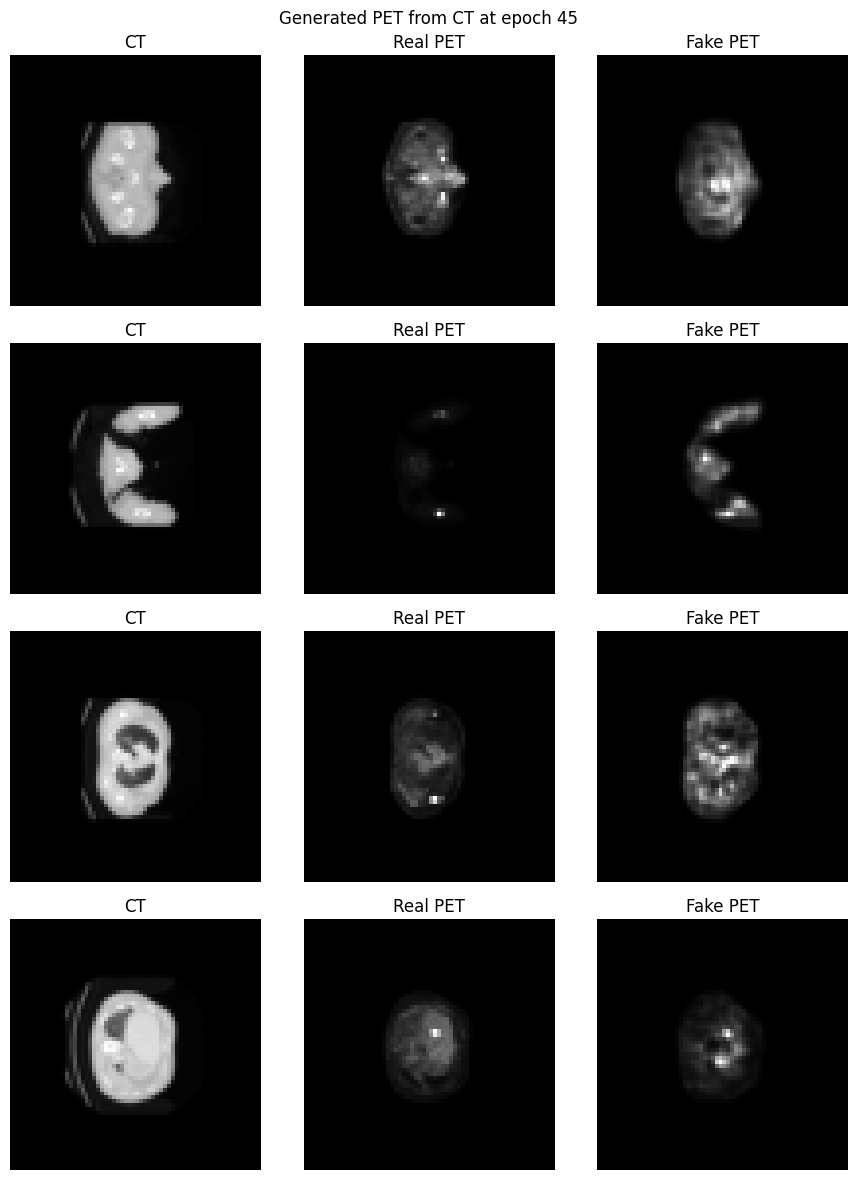

Epoch [46/100] | D: 0.2881 | G: 4.1127 | D_val: 0.6325 | G_val: 2.6352
[Epoch 46] PATIENCE | wait = 10/50
Epoch [47/100] | D: 0.3166 | G: 4.1015 | D_val: 0.6171 | G_val: 2.6671
[Epoch 47] PATIENCE | wait = 11/50
Epoch [48/100] | D: 0.2886 | G: 4.1630 | D_val: 0.9378 | G_val: 4.0598
[Epoch 48] PATIENCE | wait = 12/50
Epoch [49/100] | D: 0.3008 | G: 4.1363 | D_val: 0.8116 | G_val: 3.5865
[Epoch 49] PATIENCE | wait = 13/50
Epoch [50/100] | D: 0.2973 | G: 4.1176 | D_val: 1.1525 | G_val: 4.3362
[Epoch 50] PATIENCE | wait = 14/50


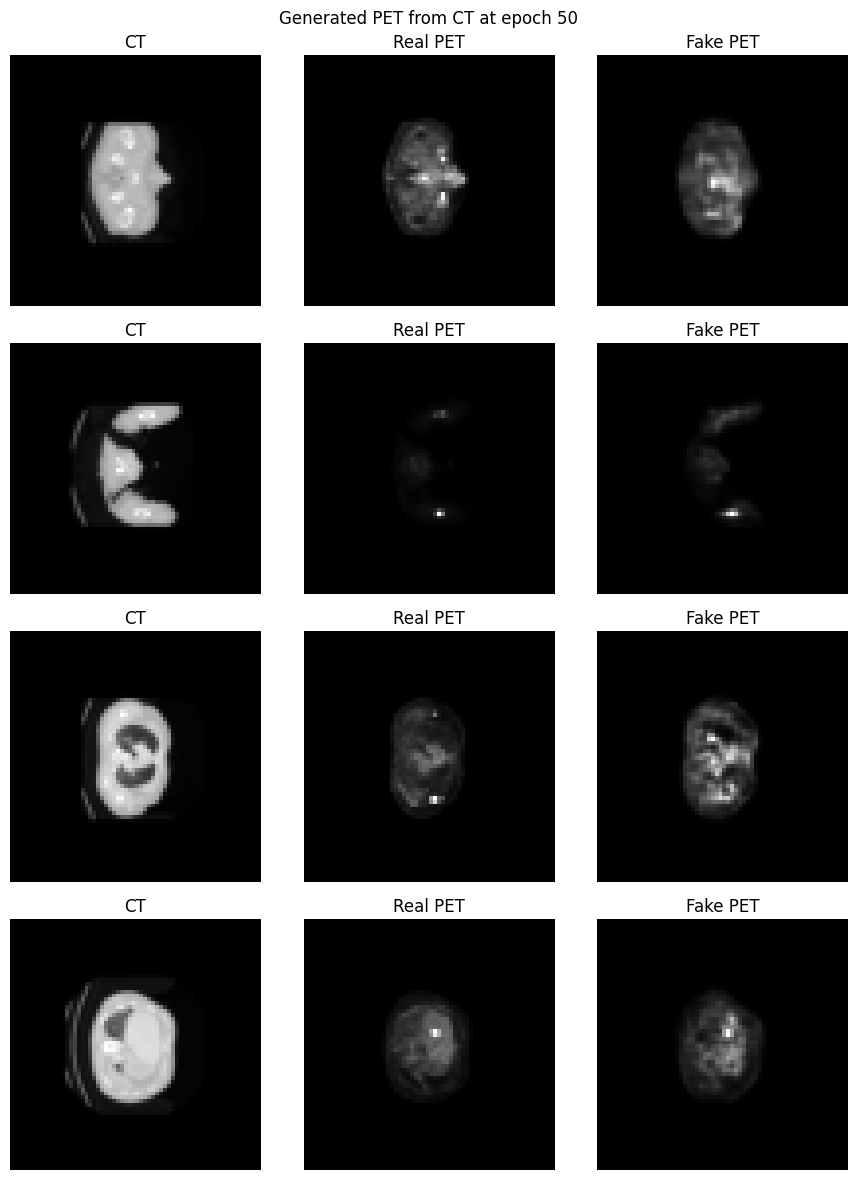

Epoch [51/100] | D: 0.3072 | G: 4.0154 | D_val: 0.6618 | G_val: 2.5481
[Epoch 51] PATIENCE | wait = 15/50
Epoch [52/100] | D: 0.3001 | G: 4.0687 | D_val: 1.3097 | G_val: 4.5910
[Epoch 52] PATIENCE | wait = 16/50
Epoch [53/100] | D: 0.2918 | G: 4.1070 | D_val: 0.6273 | G_val: 2.9045
[Epoch 53] PATIENCE | wait = 17/50
Epoch [54/100] | D: 0.3013 | G: 4.0940 | D_val: 0.8822 | G_val: 3.4169
[Epoch 54] PATIENCE | wait = 18/50
Epoch [55/100] | D: 0.2819 | G: 4.2180 | D_val: 0.6192 | G_val: 2.7932
[Epoch 55] PATIENCE | wait = 19/50


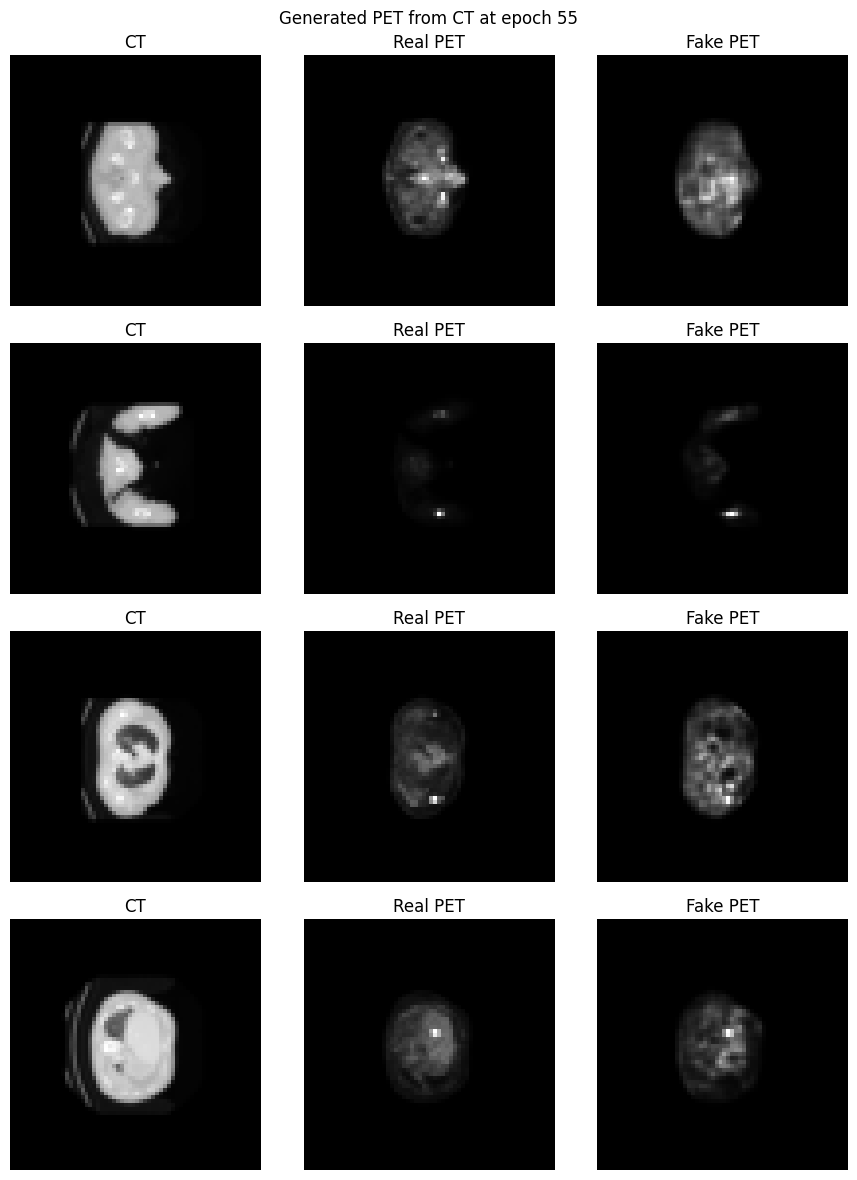

Epoch [56/100] | D: 0.2819 | G: 4.1634 | D_val: 0.7405 | G_val: 3.3653
[Epoch 56] PATIENCE | wait = 20/50
Epoch [57/100] | D: 0.3137 | G: 4.0241 | D_val: 0.7455 | G_val: 3.1807
[Epoch 57] PATIENCE | wait = 21/50
Epoch [58/100] | D: 0.3041 | G: 4.0379 | D_val: 0.9201 | G_val: 3.8184
[Epoch 58] PATIENCE | wait = 22/50
Epoch [59/100] | D: 0.2647 | G: 4.2043 | D_val: 0.6082 | G_val: 2.6679
[Epoch 59] PATIENCE | wait = 23/50
Epoch [60/100] | D: 0.2825 | G: 4.2490 | D_val: 1.1301 | G_val: 3.9553
[Epoch 60] PATIENCE | wait = 24/50


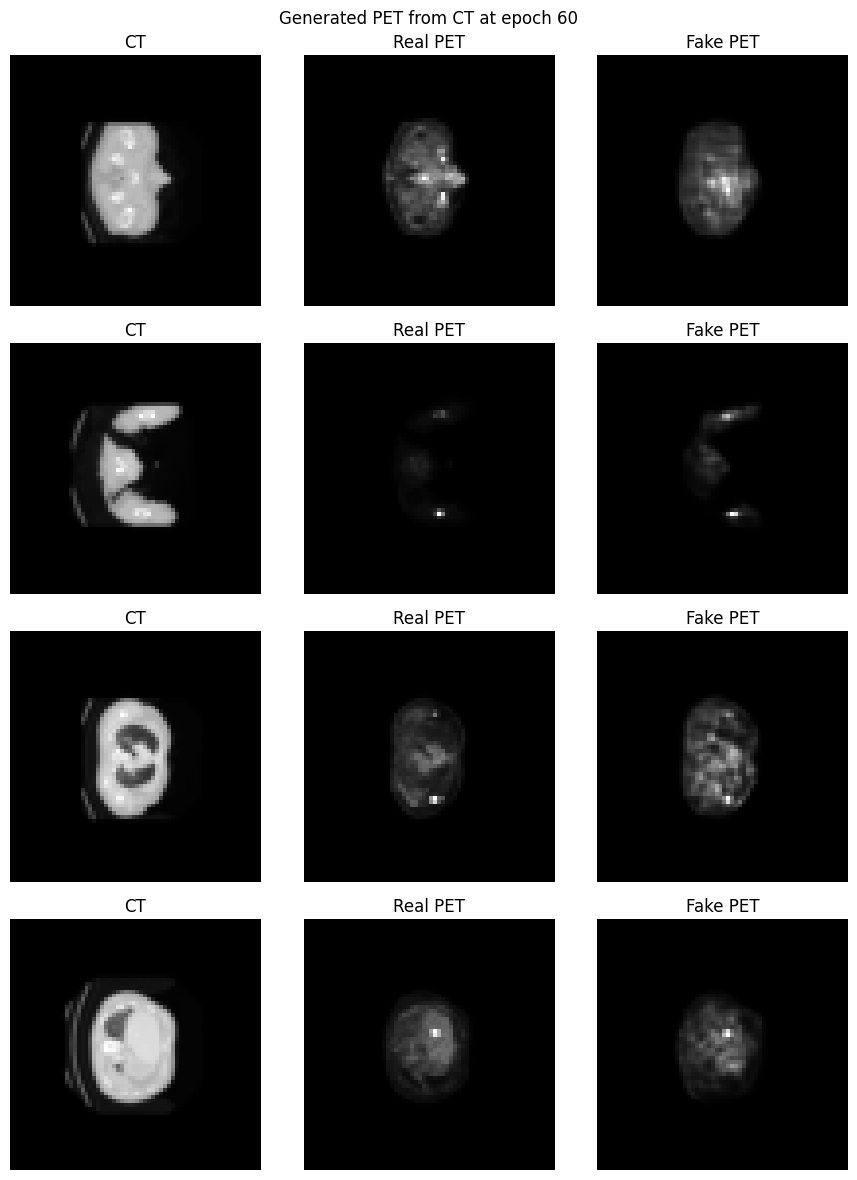

Epoch [61/100] | D: 0.2847 | G: 4.1020 | D_val: 0.7325 | G_val: 2.7376
[Epoch 61] PATIENCE | wait = 25/50
Epoch [62/100] | D: 0.3195 | G: 4.1039 | D_val: 0.7093 | G_val: 2.5558
[Epoch 62] PATIENCE | wait = 26/50
Epoch [63/100] | D: 0.2988 | G: 3.9829 | D_val: 0.7282 | G_val: 2.8360
[Epoch 63] PATIENCE | wait = 27/50
Epoch [64/100] | D: 0.2772 | G: 4.1839 | D_val: 0.6905 | G_val: 3.0824
[Epoch 64] PATIENCE | wait = 28/50
Epoch [65/100] | D: 0.3020 | G: 4.0483 | D_val: 0.8507 | G_val: 3.5877
[Epoch 65] PATIENCE | wait = 29/50


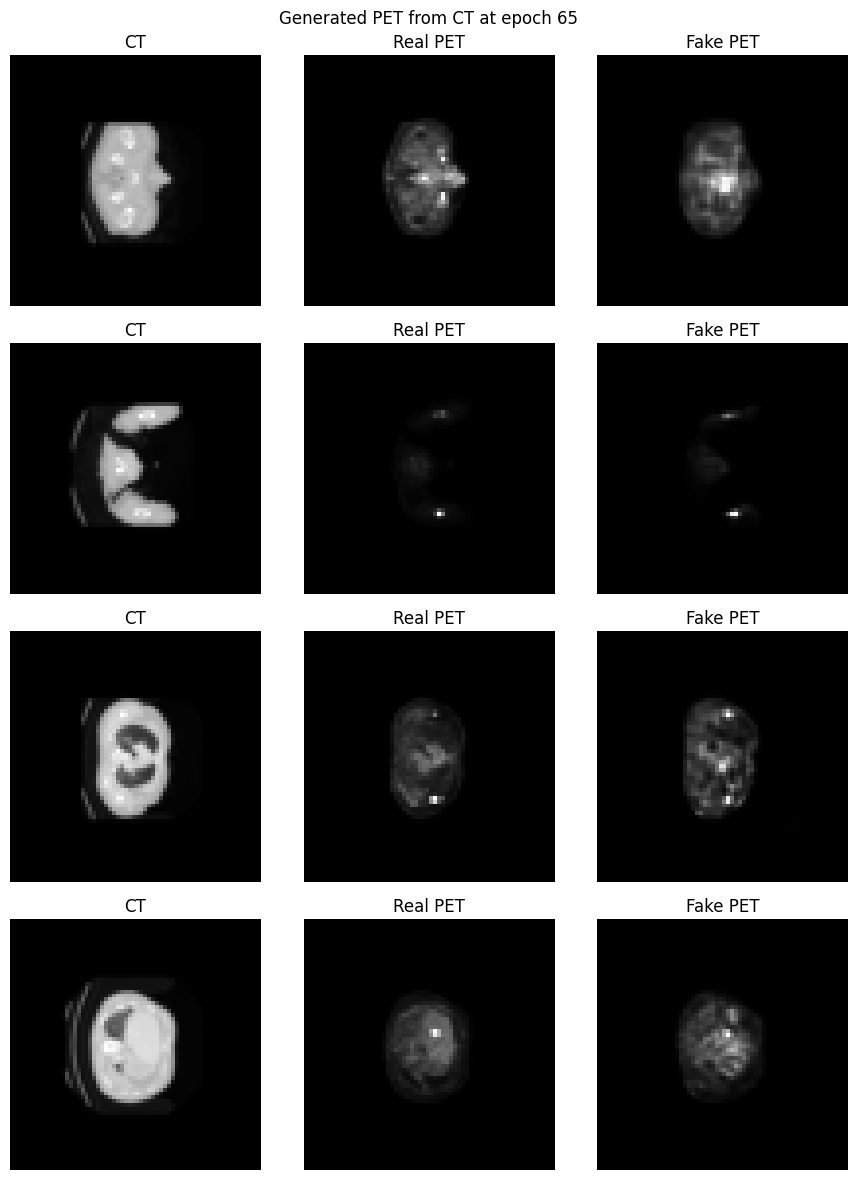

Epoch [66/100] | D: 0.2536 | G: 4.2980 | D_val: 0.7201 | G_val: 3.3169
[Epoch 66] PATIENCE | wait = 30/50
Epoch [67/100] | D: 0.3139 | G: 4.0349 | D_val: 0.6587 | G_val: 2.5312
[Epoch 67] PATIENCE | wait = 31/50
Epoch [68/100] | D: 0.2711 | G: 4.1384 | D_val: 0.7910 | G_val: 3.5752
[Epoch 68] PATIENCE | wait = 32/50
Epoch [69/100] | D: 0.2700 | G: 4.2245 | D_val: 0.9449 | G_val: 3.8552
[Epoch 69] PATIENCE | wait = 33/50
Epoch [70/100] | D: 0.3024 | G: 4.1088 | D_val: 1.1408 | G_val: 4.2037
[Epoch 70] PATIENCE | wait = 34/50


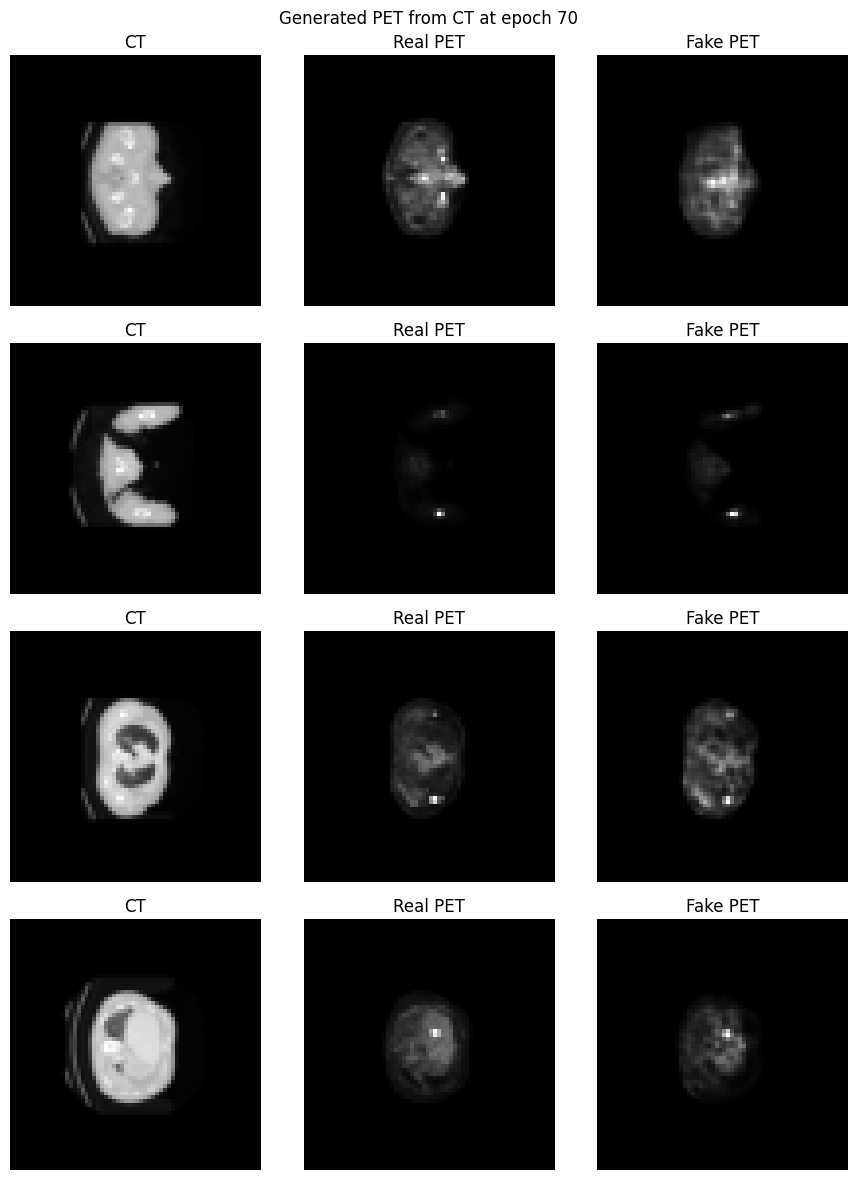

Epoch [71/100] | D: 0.2942 | G: 4.1118 | D_val: 0.6865 | G_val: 2.7299
[Epoch 71] PATIENCE | wait = 35/50
Epoch [72/100] | D: 0.2981 | G: 4.1320 | D_val: 1.1687 | G_val: 4.1708
[Epoch 72] PATIENCE | wait = 36/50
Epoch [73/100] | D: 0.3115 | G: 3.9330 | D_val: 0.8564 | G_val: 2.0464
[Epoch 73] PATIENCE | improvement detected → reset wait
Epoch [74/100] | D: 0.2526 | G: 4.2538 | D_val: 1.4472 | G_val: 5.1915
[Epoch 74] PATIENCE | wait = 1/50
Epoch [75/100] | D: 0.3045 | G: 4.1601 | D_val: 0.9984 | G_val: 3.7772
[Epoch 75] PATIENCE | wait = 2/50


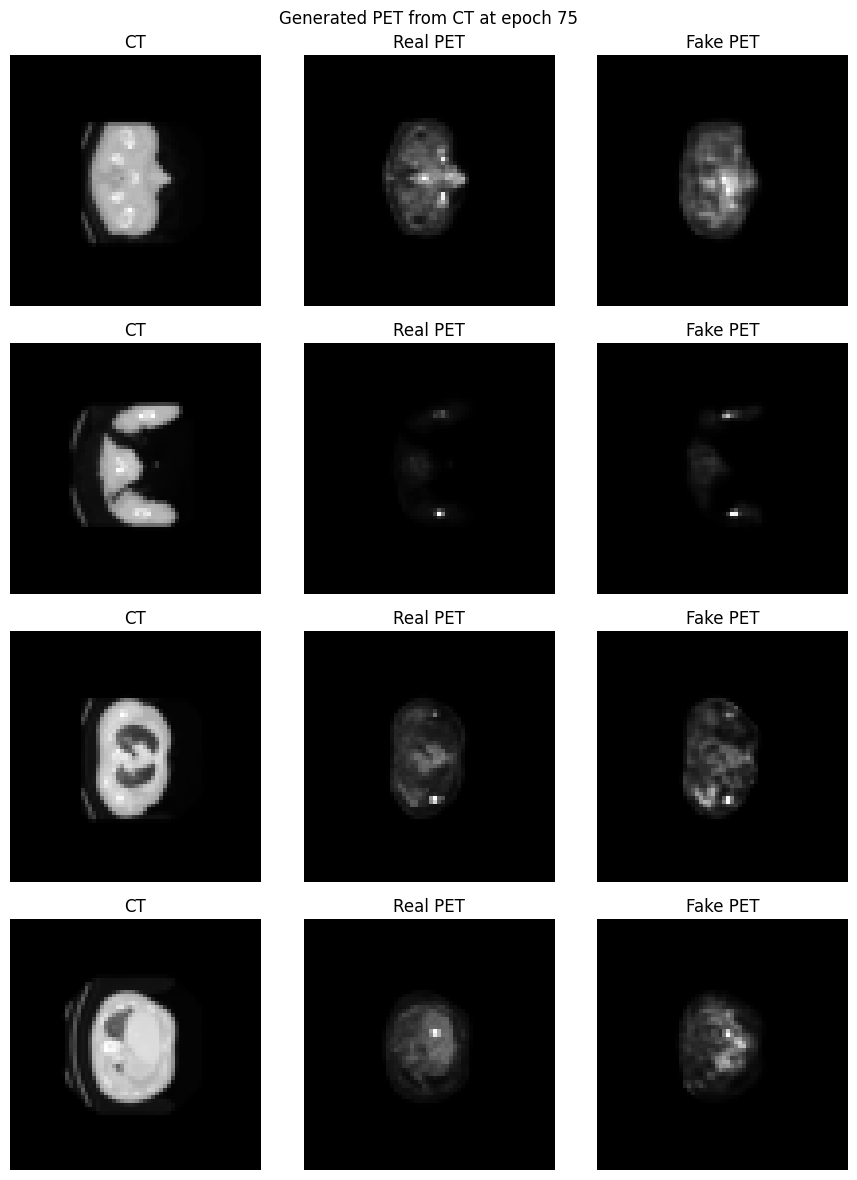

Epoch [76/100] | D: 0.3375 | G: 3.8801 | D_val: 0.7809 | G_val: 3.3019
[Epoch 76] PATIENCE | wait = 3/50
Epoch [77/100] | D: 0.2607 | G: 4.1609 | D_val: 0.6539 | G_val: 3.2277
[Epoch 77] PATIENCE | wait = 4/50
Epoch [78/100] | D: 0.2538 | G: 4.2655 | D_val: 0.6425 | G_val: 2.9152
[Epoch 78] PATIENCE | wait = 5/50
Epoch [79/100] | D: 0.2796 | G: 4.2431 | D_val: 0.6536 | G_val: 2.6653
[Epoch 79] PATIENCE | wait = 6/50
Epoch [80/100] | D: 0.2817 | G: 4.1640 | D_val: 0.9198 | G_val: 3.4299
[Epoch 80] PATIENCE | wait = 7/50


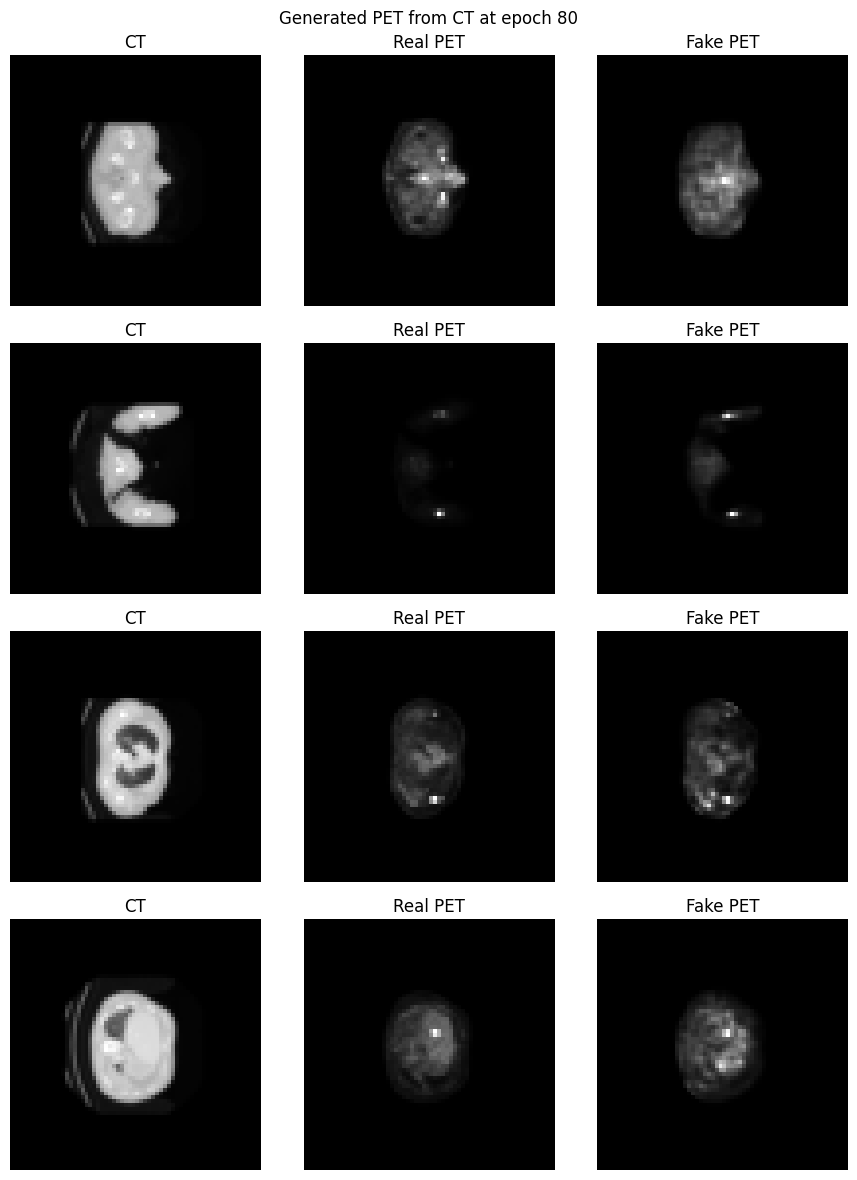

Epoch [81/100] | D: 0.2800 | G: 4.1507 | D_val: 0.7025 | G_val: 2.5657
[Epoch 81] PATIENCE | wait = 8/50
Epoch [82/100] | D: 0.3118 | G: 3.9809 | D_val: 0.6832 | G_val: 2.9599
[Epoch 82] PATIENCE | wait = 9/50
Epoch [83/100] | D: 0.2711 | G: 4.1452 | D_val: 1.0677 | G_val: 4.2474
[Epoch 83] PATIENCE | wait = 10/50
Epoch [84/100] | D: 0.2487 | G: 4.3844 | D_val: 0.7030 | G_val: 3.1946
[Epoch 84] PATIENCE | wait = 11/50
Epoch [85/100] | D: 0.2707 | G: 4.2075 | D_val: 0.7123 | G_val: 2.9666
[Epoch 85] PATIENCE | wait = 12/50


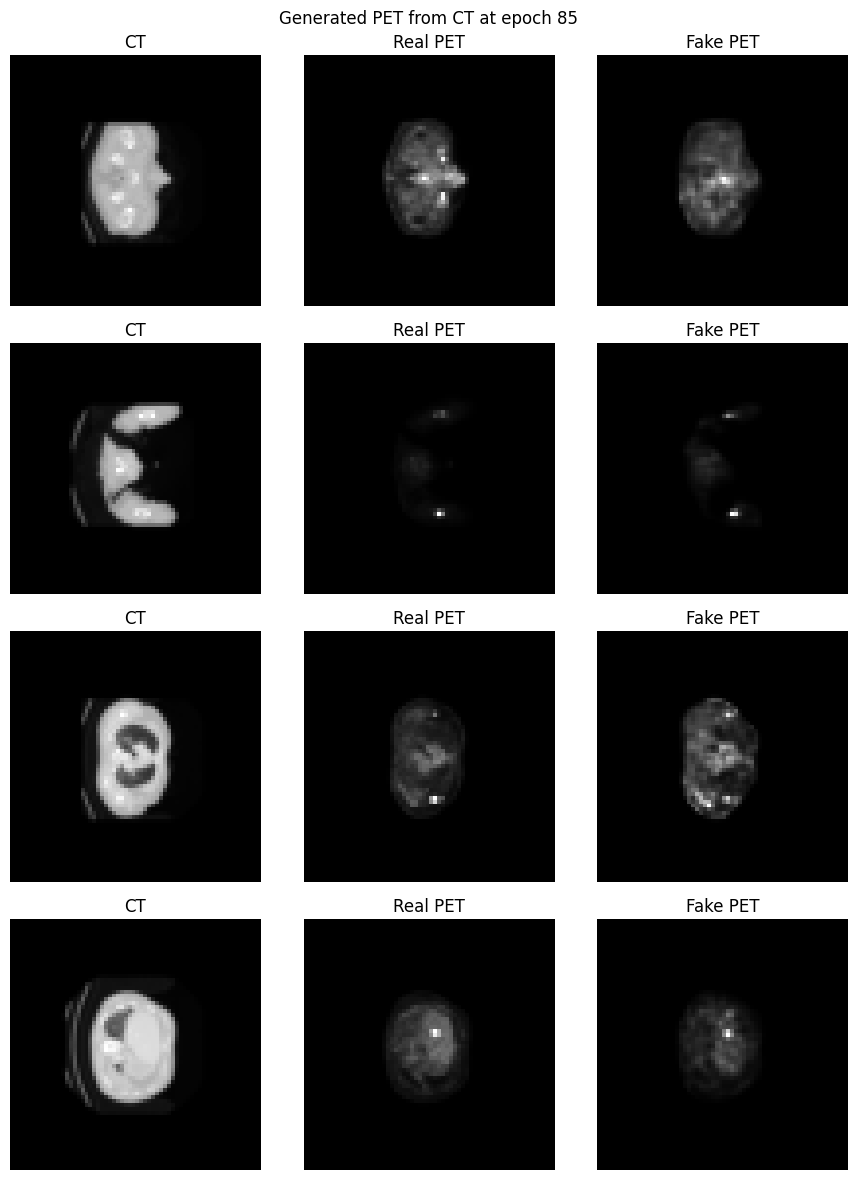

Epoch [86/100] | D: 0.2890 | G: 4.1294 | D_val: 1.3377 | G_val: 5.0070
[Epoch 86] PATIENCE | wait = 13/50
Epoch [87/100] | D: 0.2783 | G: 4.2197 | D_val: 1.1493 | G_val: 4.5202
[Epoch 87] PATIENCE | wait = 14/50
Epoch [88/100] | D: 0.2630 | G: 4.2595 | D_val: 0.6792 | G_val: 3.1874
[Epoch 88] PATIENCE | wait = 15/50
Epoch [89/100] | D: 0.2659 | G: 4.3358 | D_val: 0.9841 | G_val: 3.9934
[Epoch 89] PATIENCE | wait = 16/50
Epoch [90/100] | D: 0.2508 | G: 4.3984 | D_val: 1.0825 | G_val: 4.2216
[Epoch 90] PATIENCE | wait = 17/50


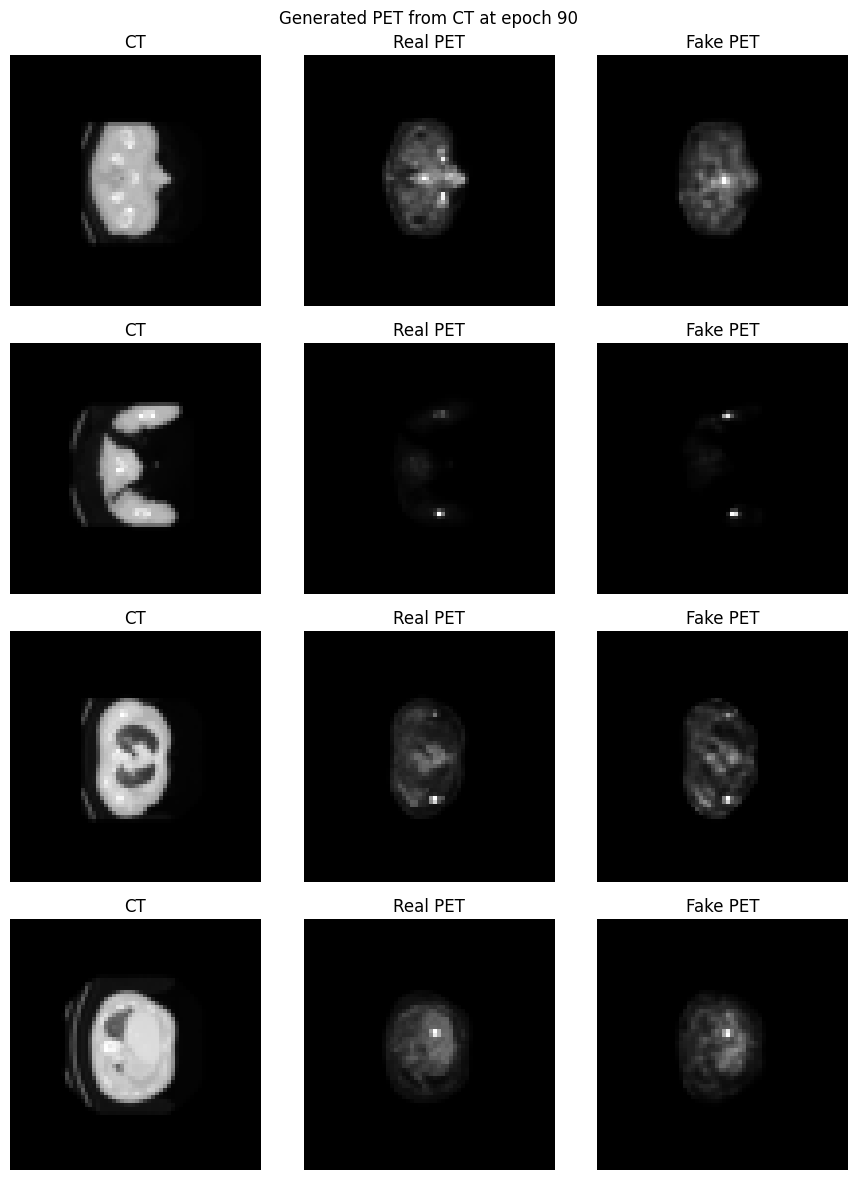

Epoch [91/100] | D: 0.2739 | G: 4.2975 | D_val: 0.7326 | G_val: 3.1587
[Epoch 91] PATIENCE | wait = 18/50
Epoch [92/100] | D: 0.2867 | G: 4.2015 | D_val: 0.9654 | G_val: 3.8272
[Epoch 92] PATIENCE | wait = 19/50
Epoch [93/100] | D: 0.2860 | G: 4.2339 | D_val: 1.1327 | G_val: 4.1260
[Epoch 93] PATIENCE | wait = 20/50
Epoch [94/100] | D: 0.2975 | G: 4.0930 | D_val: 0.7424 | G_val: 3.0790
[Epoch 94] PATIENCE | wait = 21/50
Epoch [95/100] | D: 0.2442 | G: 4.3812 | D_val: 0.6750 | G_val: 2.9675
[Epoch 95] PATIENCE | wait = 22/50


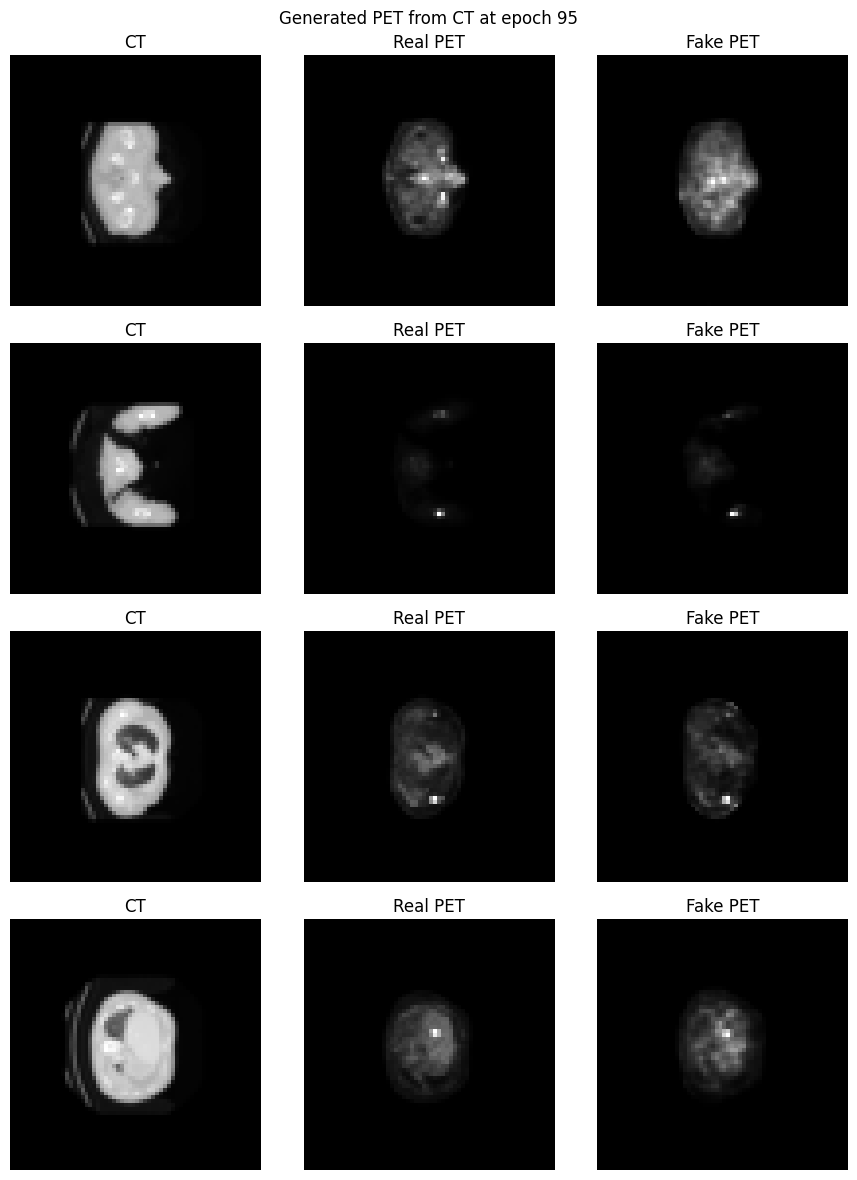

Epoch [96/100] | D: 0.2379 | G: 4.5003 | D_val: 1.3769 | G_val: 4.9655
[Epoch 96] PATIENCE | wait = 23/50
Epoch [97/100] | D: 0.2351 | G: 4.5306 | D_val: 0.9062 | G_val: 4.0390
[Epoch 97] PATIENCE | wait = 24/50
Epoch [98/100] | D: 0.2469 | G: 4.4369 | D_val: 0.6780 | G_val: 2.6277
[Epoch 98] PATIENCE | wait = 25/50
Epoch [99/100] | D: 0.2782 | G: 4.3008 | D_val: 0.6991 | G_val: 2.7289
[Epoch 99] PATIENCE | wait = 26/50
Epoch [100/100] | D: 0.2832 | G: 4.2990 | D_val: 1.2896 | G_val: 4.7459
[Epoch 100] PATIENCE | wait = 27/50


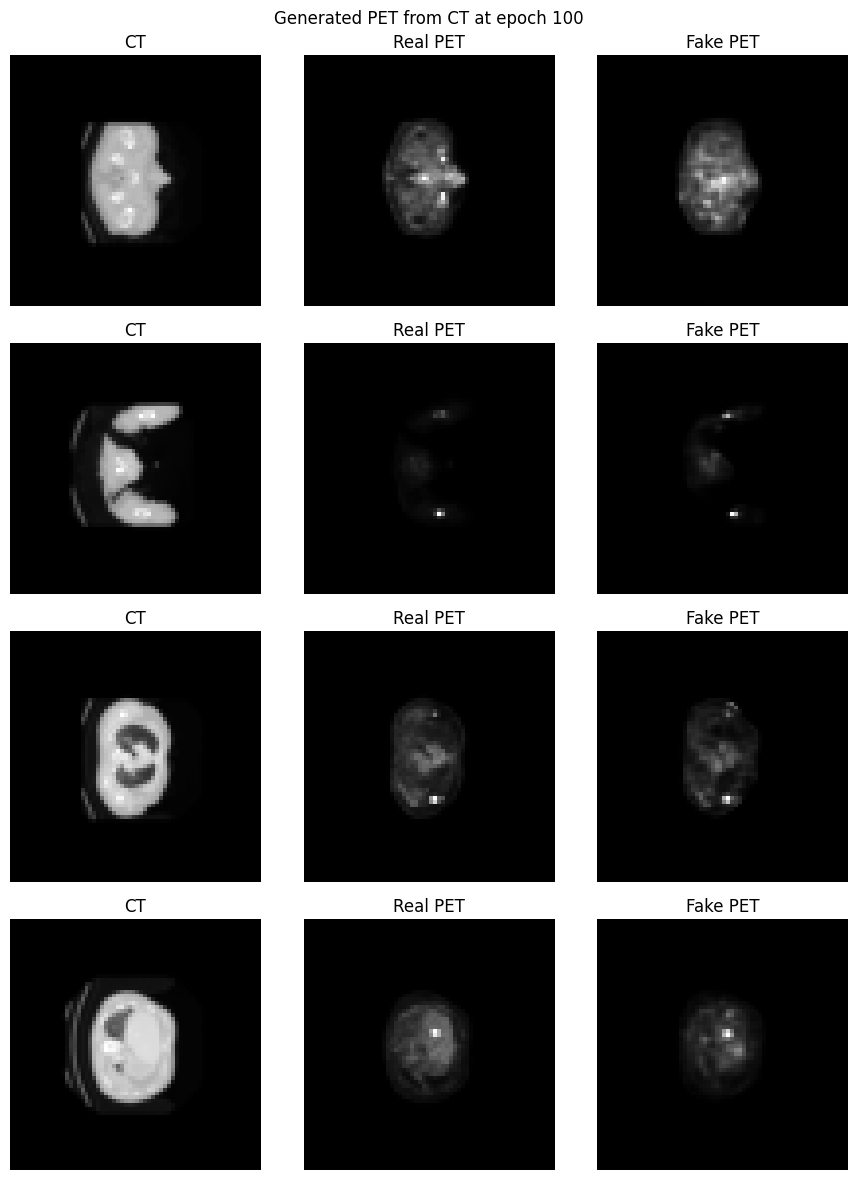

Best weights restored.


In [10]:
history = train_cgan(
    generator=G,
    discriminator=D,
    train_loader=train_loader,
    val_loader=val_loader,
    n_epochs=n_epochs,
    patience=50,
    warmup=10
)

## 8. Plot training losses   

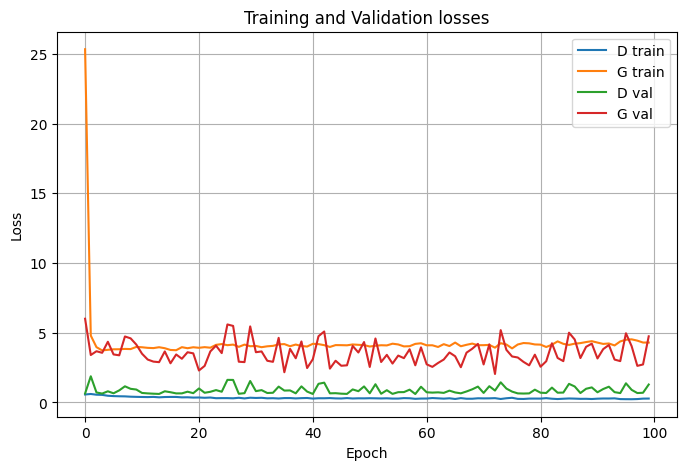

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(history['d_loss'], label='D train')
plt.plot(history['g_loss'], label='G train')
plt.plot(history['d_val'], label='D val')
plt.plot(history['g_val'], label='G val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation losses')
plt.legend()
plt.grid(True)
plt.show()

## 9. Conditional generation after training

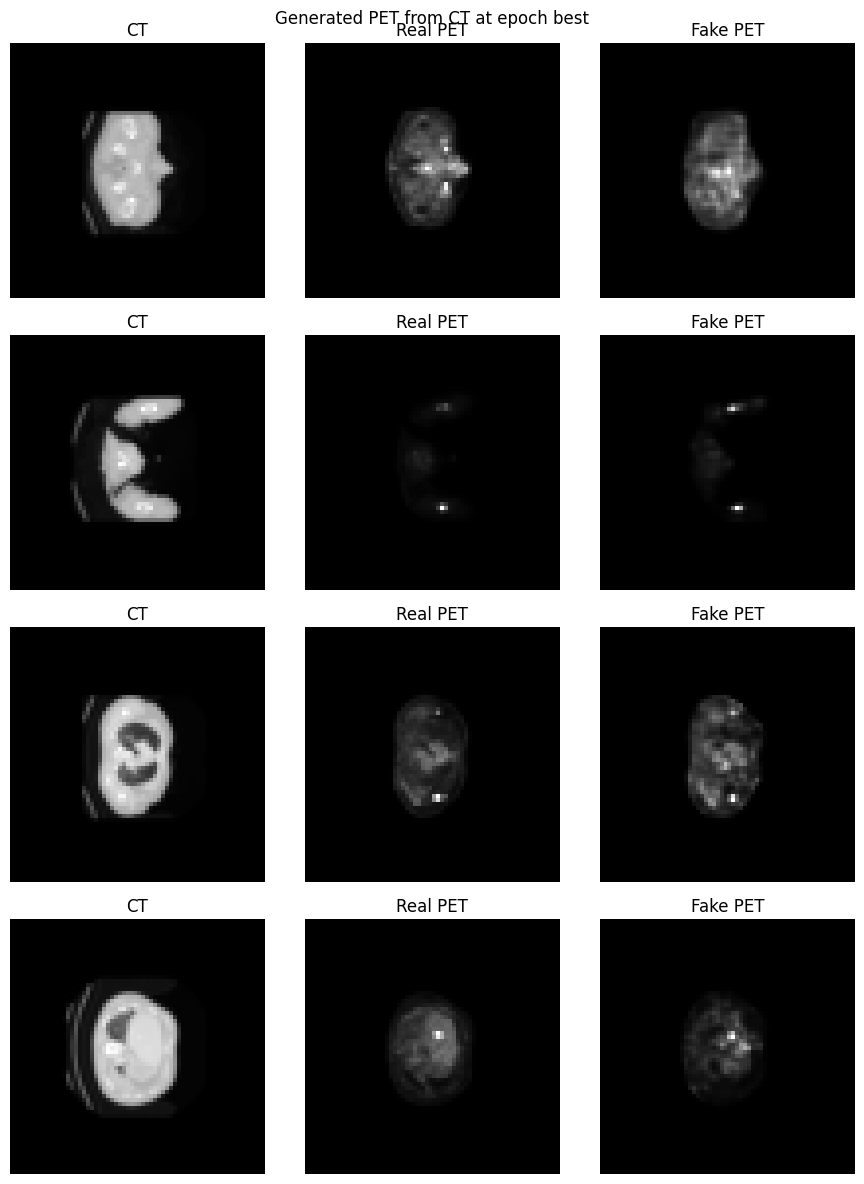

In [12]:
summarize_performance(G, val_loader, epoch="best", n_samples=6)

## 10. Quantitative evaluation


In [13]:
#computes PSNR(the higher the better) and SSIM(closer to 1 better) on validation data, uses restored best generator
mean_psnr, mean_ssim = evaluate_generator(G, val_loader, device)


Mean PSNR on validation data: 37.0096
Mean SSIM on validation data: 0.9632
